In [1]:
# Parameters
BATCH_MODE = "true"


# App-2 : Coloration de Graphes

**Navigation** : [<< App-1 NQueens](App-1-NQueens.ipynb) | [Index](../../README.md) | [App-3 NurseScheduling >>](App-3-NurseScheduling.ipynb)

## Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. **Formaliser** un problème de coloration de graphe comme CSP
2. **Implementer** l'algorithme Greedy et comparer les effets de l'ordre des sommets
3. **Implementer** DSATUR (Brelaz 1979) et comprendre son avantage heuristique
4. **Modeliser** le problème avec OR-Tools CP-SAT et prouver l'optimalite
5. **Appliquer** ces algorithmes a la coloration des departements francais
6. **Comparer** les performances sur des graphes aleatoires de taille croissante

### Prerequis
- Python 3.10+, notions de graphes (sommets, aretes, adjacence)
- [CSP-1 : Fundamentals](../../Part2-CSP/CSP-1-Fundamentals.ipynb) et [CSP-2 : Consistency](../../Part2-CSP/CSP-2-Consistency.ipynb)

### Duree estimee : 45 minutes

***

## 1. Introduction (~5 min)

### Le problème de coloration de graphe

La **coloration de graphe** consiste a attribuer une couleur a chaque sommet d'un graphe de sorte que deux sommets adjacents (relies par une arete) n'aient jamais la même couleur. Le nombre minimum de couleurs necessaires s'appelle le **nombre chromatique** $\chi(G)$.

**Definition formelle** :

Soit $G = (V, E)$ un graphe. Une $k$-coloration est une fonction $c : V \to \{1, 2, \ldots, k\}$ telle que :

$$\forall (u, v) \in E, \quad c(u) \neq c(v)$$

Le nombre chromatique est :

$$\chi(G) = \min \{ k : \text{il existe une } k\text{-coloration valide de } G \}$$

### Applications concretes

| Domaine | Problème | Modelisation |
|---------|----------|--------------|
| **Cartographie** | Colorier une carte (regions adjacentes différentes) | Sommets = regions, aretes = frontieres communes |
| **Compilation** | Allocation de registres CPU | Sommets = variables vivantes, aretes = interferences |
| **Planification** | Emplois du temps sans conflit | Sommets = cours, aretes = même professeur ou salle |
| **Telecommunications** | Attribution de frequences radio | Sommets = antennes, aretes = zones d'interference |

### Complexite

- Determiner si un graphe est **2-coloriable** (biparti) est en $O(\vert V\vert + \vert E\vert)$ -- polynomial
- Determiner si un graphe est **3-coloriable** est **NP-complet** (Karp, 1972)
- Calculer $\chi(G)$ est donc **NP-difficile** en general
- Le **theoreme des quatre couleurs** (1976) garantit que tout graphe **planaire** est 4-coloriable

Dans ce notebook, nous comparons trois approches : un algorithme glouton simple, l'heuristique DSATUR, et un solveur exact CP-SAT.

In [2]:
# Dependencies pre-provisionnees (numpy matplotlib pandas mealpy networkx ortools) : voir requirements.txt.
# Aucun install requis dans le notebook ; import et invalidation des caches ci-dessous.

import importlib, site
importlib.invalidate_caches()

### Visualisation du coloriage

Cette premiere figure place le decor : elle dessine le graphe que tout le notebook va colorer, celui des
departements francais d'Ile-de-France et des regions voisines (un sous-ensemble de 18 sommets et 37 aretes —
ces chiffres sont mesures par la cellule suivante).

Ce qu'il faut regarder avant de commencer :

- **Chaque sommet = un departement.** La position approximative du sommet evoque sa geographie, ce qui rend la
  planaite du graphe naturelle : deux departements qui se touchent physiquement se voient relies par une arete.
- **Une arete = une frontiere partagee.** Deux departements voisins ne peuvent pas recevoir la meme couleur :
  c'est la definition meme d'une coloration valide, celle que tous les algorithmes de ce notebook vont garantir.
- **La question du coloriage.** Combien de couleurs faut-il, au minimum, pour colorer la carte entiere ?
  Le theoreme des quatre couleurs promet qu'un graphe planaire se colore toujours avec au plus 4 couleurs —
  la suite va verifier ce plafond sur les donnees reelles.


In [3]:
# Imports pour tout le notebook
import sys
import time
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
import os
from collections import defaultdict

# OR-Tools CP-SAT
from ortools.sat.python import cp_model

# Helpers partages de la serie Search
sys.path.insert(0, os.path.abspath('../..'))
from search_helpers import benchmark_table, plot_benchmark

# Reproductibilite
random.seed(42)
np.random.seed(42)

print("Imports OK")
print(f"NetworkX version : {nx.__version__}")

Imports OK
NetworkX version : 3.6.1


***

## 2. Construction du graphe : departements francais (~5 min)

Nous utilisons un sous-ensemble de departements francais metropolitains pour illustrer le probleme. Chaque
departement est un sommet, et deux departements sont relies par une arete s'ils partagent une frontiere commune.

Nous construisons un graphe de **18 departements** autour de l'Ile-de-France et de ses voisins. La cellule
suivante construit ce graphe a partir des frontieres reelles, puis mesure ses caracteristiques structurelles :
nombre de sommets, d'aretes, degres minimaux et maximaux, et le test de planarite (NetworkX le fait en
detectant les subdivisions de K5 et de K3,3).

C'est l'occasion de fixer le vocabulaire CSP que le notebook utilisera ensuite :

- **Variables** : les sommets du graphe, un par departement.
- **Domaine** : l'ensemble des couleurs disponibles (on ne le borne pas a priori — les algorithmes l'etendent au besoin).
- **Contraintes** : pour chaque arete (u, v), la contrainte binaire couleur(u) != couleur(v).

Tout le reste — l'ordre de traitement des sommets, la strategie de choix, la recherche d'optimalite — n'est que
des politiques differentes pour explorer ce meme probleme.


**Pourquoi ce graphe plutot qu'un autre ?** Quatre raisons pedagogiques : (1) il est **planaire** — le theoreme
des quatre couleurs garantit que 4 couleurs suffisent, ce qui donne une borne superieure connue a l'avance pour
verifier les heuristiques ; (2) il est suffisamment **asymetrique** (degres de 2 a 9) pour que l'ordre de traitement
du greedy fasse reellement varier le resultat — c'est la lecon centrale de la section 3 ; (3) il est assez petit
(18 sommets) pour que CP-SAT prouve l'optimalite en quelques dizaines de millisecondes ; et (4) sa realite
geographique rend chaque affectation **verifiable a l'oeil** sur la carte finale.

Ce triplet — borne planaire connue, asymetrie suffisante, taille resolvable — est exactement ce qui fait un bon
terrain d'experience pour comparer des heuristiques a un solveur exact.

In [4]:
# Graphe des departements francais (sous-ensemble)
# Chaque cle est un departement, la valeur est la liste des departements adjacents

DEPARTMENTS_ADJACENCY = {
    "Paris":          ["Hauts-de-Seine", "Seine-Saint-Denis", "Val-de-Marne"],
    "Hauts-de-Seine": ["Paris", "Seine-Saint-Denis", "Val-de-Marne", "Yvelines", "Val-d'Oise"],
    "Seine-Saint-Denis": ["Paris", "Hauts-de-Seine", "Val-de-Marne", "Val-d'Oise", "Seine-et-Marne"],
    "Val-de-Marne":   ["Paris", "Hauts-de-Seine", "Seine-Saint-Denis", "Essonne", "Seine-et-Marne"],
    "Essonne":        ["Val-de-Marne", "Yvelines", "Seine-et-Marne", "Loiret"],
    "Yvelines":       ["Hauts-de-Seine", "Essonne", "Val-d'Oise", "Eure", "Eure-et-Loir"],
    "Val-d'Oise":     ["Hauts-de-Seine", "Seine-Saint-Denis", "Yvelines", "Oise"],
    "Seine-et-Marne": ["Seine-Saint-Denis", "Val-de-Marne", "Essonne", "Loiret", "Aisne", "Oise", "Marne", "Aube", "Yonne"],
    "Oise":           ["Val-d'Oise", "Seine-et-Marne", "Aisne", "Somme"],
    "Aisne":          ["Oise", "Seine-et-Marne", "Marne", "Somme", "Nord"],
    "Loiret":         ["Essonne", "Seine-et-Marne", "Yonne", "Eure-et-Loir"],
    "Eure-et-Loir":   ["Yvelines", "Loiret", "Eure"],
    "Eure":           ["Yvelines", "Eure-et-Loir", "Oise"],
    "Marne":          ["Seine-et-Marne", "Aisne", "Aube"],
    "Aube":           ["Seine-et-Marne", "Marne", "Yonne"],
    "Yonne":          ["Seine-et-Marne", "Loiret", "Aube"],
    "Somme":          ["Oise", "Aisne", "Nord"],
    "Nord":           ["Aisne", "Somme"]
}

def build_department_graph():
    """Construit le graphe NetworkX des departements."""
    G = nx.Graph()
    for dept, neighbors in DEPARTMENTS_ADJACENCY.items():
        G.add_node(dept)
        for neighbor in neighbors:
            G.add_edge(dept, neighbor)
    return G

dept_graph = build_department_graph()

print(f"Graphe des departements")
print(f"=" * 40)
print(f"Sommets    : {dept_graph.number_of_nodes()}")
print(f"Aretes     : {dept_graph.number_of_edges()}")
print(f"Degre max  : {max(dict(dept_graph.degree()).values())}")
print(f"Degre min  : {min(dict(dept_graph.degree()).values())}")
print(f"Degre moy  : {sum(dict(dept_graph.degree()).values()) / dept_graph.number_of_nodes():.1f}")
print(f"Planaire   : {nx.is_planar(dept_graph)}")
print(f"\nDegres par departement :")
for dept, deg in sorted(dept_graph.degree(), key=lambda x: -x[1]):
    print(f"  {dept:<22} degre {deg}")

Graphe des departements
Sommets    : 18
Aretes     : 37
Degre max  : 9
Degre min  : 2
Degre moy  : 4.1
Planaire   : True

Degres par departement :
  Seine-et-Marne         degre 9
  Hauts-de-Seine         degre 5
  Seine-Saint-Denis      degre 5
  Val-de-Marne           degre 5
  Yvelines               degre 5
  Oise                   degre 5
  Aisne                  degre 5
  Val-d'Oise             degre 4
  Essonne                degre 4
  Loiret                 degre 4
  Paris                  degre 3
  Eure                   degre 3
  Eure-et-Loir           degre 3
  Marne                  degre 3
  Aube                   degre 3
  Yonne                  degre 3
  Somme                  degre 3
  Nord                   degre 2


### Interpretation : structure du graphe

La mesure de la cellule precedente donne les **18 sommets, 37 aretes** du sous-ensemble de departements retenu.
Trois chiffres structurent la suite :

| Mesure | Valeur | Ce qu'elle annonce |
|---|---|---|
| **Degre max** | 9 (Seine-et-Marne) | Sommet le plus contraint : 9 voisins, donc 9 couleurs interdites quand on le colorera — candidat naturel pour etre traite en premier (strategie de DSATUR) |
| **Degre min** | 2 (Nord) | Sommet le plus libre : il garde presque toutes ses options jusqu'au bout |
| **Degre moyen** | 4.1 | Un graphe localement peu dense : la moyenne est loin du maximal 9 |

La planarite (``Planaire : True``) est la propriete la plus importante : elle garantit par le theoreme des quatre
couleurs qu'une coloration a **4 couleurs** existe — c'est la borne superieure que greedy et DSATUR vont chacun
rattraper, et que CP-SAT prouvera optimale.


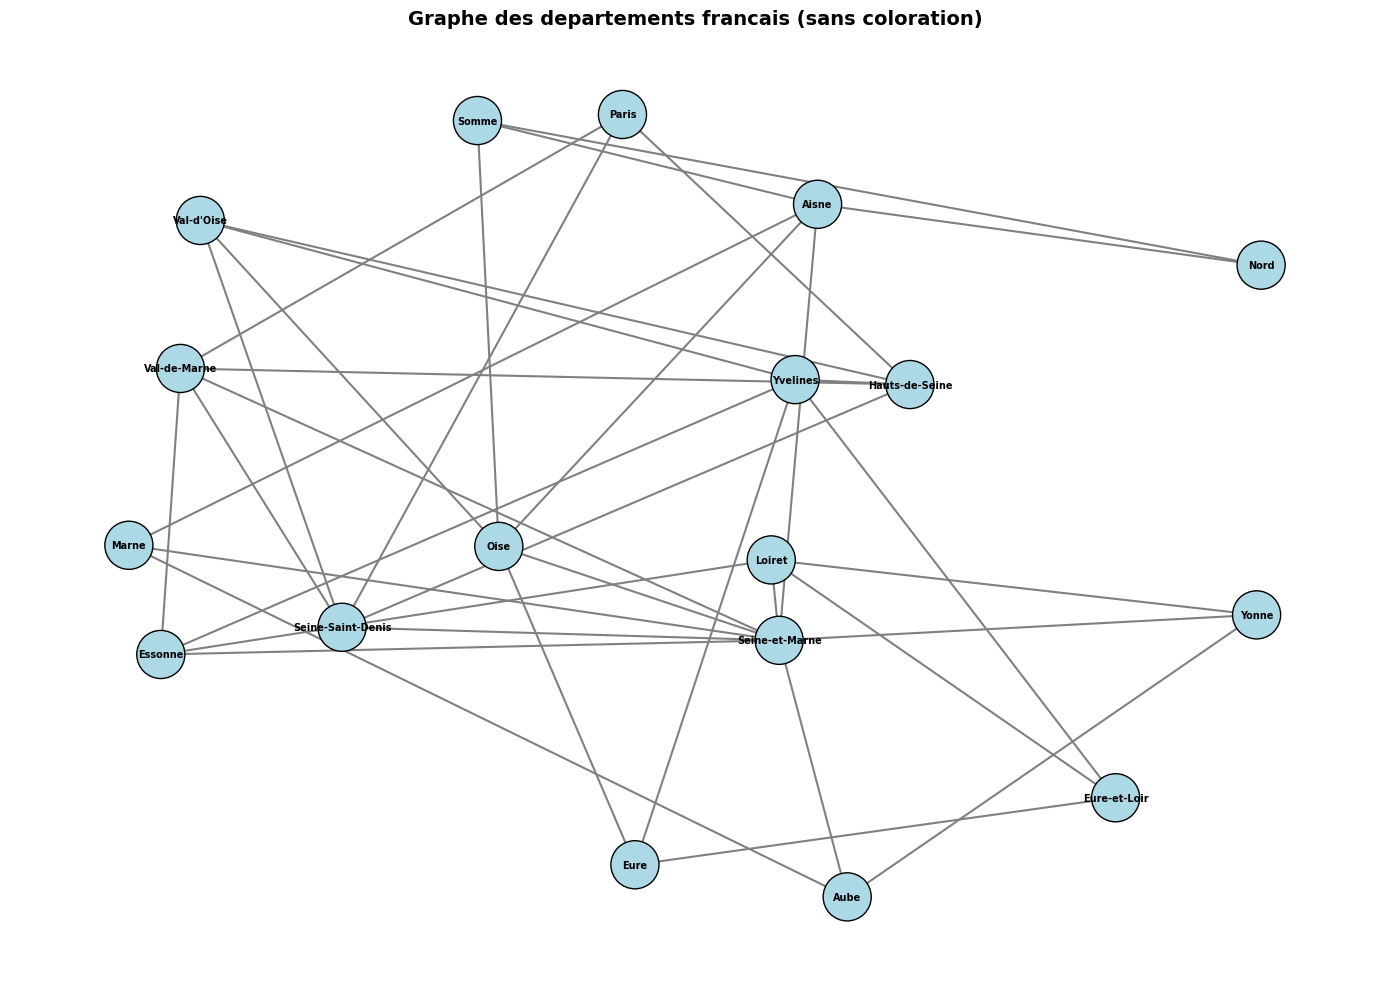

In [5]:
# Visualisation du graphe des departements

def draw_graph(G, coloring=None, title="Graphe", figsize=(14, 10)):
    """Dessine un graphe avec coloration optionnelle.
    
    Args:
        G: graphe NetworkX
        coloring: dict sommet -> numero de couleur (int), ou None
        title: titre du graphique
        figsize: taille de la figure
    """
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    
    # Palette de couleurs distinctes
    palette = [
        '#FF6B6B',  # rouge
        '#4ECDC4',  # turquoise
        '#45B7D1',  # bleu clair
        '#FFA07A',  # saumon
        '#98D8C8',  # vert menthe
        '#F7DC6F',  # jaune
        '#BB8FCE',  # violet
        '#85C1E9',  # bleu pale
        '#F0B27A',  # orange
        '#AED6F1',  # bleu tres pale
    ]
    
    pos = nx.spring_layout(G, seed=42, k=2.0)
    
    if coloring:
        node_colors = [palette[coloring.get(node, 0) % len(palette)] for node in G.nodes()]
    else:
        node_colors = ['#ADD8E6'] * G.number_of_nodes()
    
    nx.draw(G, pos, ax=ax,
            with_labels=True,
            node_color=node_colors,
            node_size=1200,
            font_size=7,
            font_weight='bold',
            edge_color='gray',
            width=1.5,
            edgecolors='black',
            linewidths=1.0)
    
    # Legende des couleurs
    if coloring:
        n_colors = max(coloring.values()) + 1
        legend_elements = [
            mpatches.Patch(facecolor=palette[i % len(palette)], edgecolor='black',
                           label=f'Couleur {i}')
            for i in range(n_colors)
        ]
        ax.legend(handles=legend_elements, loc='upper left', fontsize=9,
                  title=f"{n_colors} couleurs")
    
    ax.set_title(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    return fig

# Afficher le graphe sans coloration
draw_graph(dept_graph, title="Graphe des departements francais (sans coloration)")
plt.show()

### Formulation CSP

Le problème de coloration se formule naturellement comme un **CSP** (Constraint Satisfaction Problem) :

| Composant | Definition | Ici |
|-----------|------------|-----|
| **Variables** $X$ | Un sommet du graphe | Chaque departement |
| **Domaines** $D_i$ | Ensemble de couleurs disponibles | $\{0, 1, \ldots, k-1\}$ |
| **Contraintes** $C$ | Deux sommets adjacents ont des couleurs différentes | $c(u) \neq c(v)$ pour chaque arete $(u, v)$ |

Nous allons resoudre ce CSP avec trois approches de complexite croissante.

***

## 3. Approche 1 : Coloration gloutonne (Greedy) (~8 min)

L'algorithme **glouton** (greedy) est la méthode la plus simple pour colorier un graphe :

1. Parcourir les sommets dans un certain ordre
2. Pour chaque sommet, attribuer la **plus petite couleur** qui n'est pas déjà utilisee par un voisin

**Proprietes** :
- Complexite : $O(\vert V\vert + \vert E\vert)$ -- très rapide
- Garantie : utilise au plus $\Delta(G) + 1$ couleurs, ou $\Delta(G)$ est le degré maximum
- Pas optimal en general : le résultat depend de l'ordre de parcours des sommets

### Algorithme

```
Pour chaque sommet v dans l'ordre choisi :
    couleurs_voisins = {couleur[u] pour u voisin de v déjà colorie}
    couleur[v] = plus petit entier >= 0 absent de couleurs_voisins
```

**Pourquoi « glouton » ?** Parce que l'algorithme prend, a chaque etape, la decision locale immédiate : donner au
sommet courant la plus petite couleur disponible, sans jamais remettre en cause les choix passes. C'est la
definition meme d'une strategie gloutonne — et sa garantie est faible : avec un ordre defavorable, le compte peut
exceder le nombre chromatique (la section suivante le mesure sur nos departements : 4 ou 5 couleurs selon l'ordre,
pour un optimum de 4).

Deux proprietes utiles a retenir pour la suite :

- **Complexite** : un seul passage sur les aretes — $O(V + E)$ — ce qui en fait l'algorithme le plus rapide de ce notebook —
  la section 6 mesure ce cout en millisecondes et le confronte aux deux autres approches.
- **Borne theorique** : dans le pire des cas, le greedy n'excede jamais $\Delta(G) + 1$ couleurs, ou $\Delta(G)$
  est le degre maximal du graphe — une borne universelle, mais tres relachee en pratique.

In [6]:
def greedy_coloring(G, order=None):
    """Coloration gloutonne d'un graphe.
    
    Args:
        G: graphe NetworkX
        order: liste ordonnee de sommets (si None, utilise l'ordre par defaut)
    
    Returns:
        dict sommet -> couleur (int), nombre de couleurs utilisees
    """
    if order is None:
        order = list(G.nodes())
    
    coloring = {}
    
    for vertex in order:
        # Couleurs utilisees par les voisins deja colories
        neighbor_colors = set()
        for neighbor in G.neighbors(vertex):
            if neighbor in coloring:
                neighbor_colors.add(coloring[neighbor])
        
        # Plus petite couleur disponible
        color = 0
        while color in neighbor_colors:
            color += 1
        
        coloring[vertex] = color
    
    n_colors = max(coloring.values()) + 1
    return coloring, n_colors


def validate_coloring(G, coloring):
    """Verifie qu'une coloration est valide (aucun conflit)."""
    for u, v in G.edges():
        if coloring.get(u) == coloring.get(v):
            return False, (u, v)
    return True, None


# Coloration gloutonne avec l'ordre par defaut
coloring_greedy, n_colors_greedy = greedy_coloring(dept_graph)
valid, conflict = validate_coloring(dept_graph, coloring_greedy)

print("Coloration Greedy (ordre par defaut)")
print("=" * 45)
print(f"Couleurs utilisees : {n_colors_greedy}")
print(f"Valide             : {valid}")
print(f"\nAffectation :")
for dept, color in sorted(coloring_greedy.items(), key=lambda x: x[1]):
    print(f"  {dept:<22} -> couleur {color}")

Coloration Greedy (ordre par defaut)
Couleurs utilisees : 4
Valide             : True

Affectation :
  Paris                  -> couleur 0
  Yvelines               -> couleur 0
  Seine-et-Marne         -> couleur 0
  Somme                  -> couleur 0
  Hauts-de-Seine         -> couleur 1
  Essonne                -> couleur 1
  Eure                   -> couleur 1
  Aisne                  -> couleur 1
  Aube                   -> couleur 1
  Seine-Saint-Denis      -> couleur 2
  Loiret                 -> couleur 2
  Oise                   -> couleur 2
  Marne                  -> couleur 2
  Nord                   -> couleur 2
  Val-de-Marne           -> couleur 3
  Val-d'Oise             -> couleur 3
  Eure-et-Loir           -> couleur 3
  Yonne                  -> couleur 3


### Impact de l'ordre des sommets

La cellule qui precede a applique greedy **dans l'ordre d'insertion** (l'ordre par defaut du graphe) : resultat,
**4 couleurs** et une affectation validee (``Valide : True``). Le parcours montre une propriete caracteristique du
greedy : les premiers sommets colores — Paris, Yvelines, Seine-et-Marne en **couleur 0** — capturent les positions
les plus disputees du graphe avant qu'elles ne se referment.

La cellule suivante teste l'hypothese centrale de cette section : **ce resultat depend-il de l'ordre choisi ?**
Elle rejoue greedy sur cinq ordres differents et compare les comptes de couleurs. C'est le point de depart de la
comparaison des algorithmes : si l'ordre change le resultat, alors un algorithme deterministe mais naif n'est pas
une reponse stable au probleme de coloration.


In [7]:
# Comparaison de differents ordres pour le greedy

def order_by_degree_desc(G):
    """Sommets tries par degre decroissant."""
    return sorted(G.nodes(), key=lambda v: G.degree(v), reverse=True)

def order_by_degree_asc(G):
    """Sommets tries par degre croissant."""
    return sorted(G.nodes(), key=lambda v: G.degree(v))

def order_random(G, seed=None):
    """Ordre aleatoire."""
    nodes = list(G.nodes())
    rng = random.Random(seed)
    rng.shuffle(nodes)
    return nodes

orders = {
    "Defaut":            list(dept_graph.nodes()),
    "Aleatoire (seed=1)": order_random(dept_graph, seed=1),
    "Aleatoire (seed=2)": order_random(dept_graph, seed=2),
    "Degre decroissant":  order_by_degree_desc(dept_graph),
    "Degre croissant":    order_by_degree_asc(dept_graph),
}

print("Impact de l'ordre sur la coloration Greedy")
print("=" * 50)
print(f"{'Ordre':<25} {'Couleurs':>10}")
print("-" * 50)

greedy_results = {}
for name, order in orders.items():
    coloring, n_colors = greedy_coloring(dept_graph, order)
    valid, _ = validate_coloring(dept_graph, coloring)
    greedy_results[name] = (coloring, n_colors)
    status = "OK" if valid else "INVALIDE"
    print(f"  {name:<25} {n_colors:>5}    ({status})")

print(f"\nObservation : le nombre de couleurs varie selon l'ordre.")

Impact de l'ordre sur la coloration Greedy
Ordre                       Couleurs
--------------------------------------------------
  Defaut                        4    (OK)
  Aleatoire (seed=1)            5    (OK)
  Aleatoire (seed=2)            5    (OK)
  Degre decroissant             4    (OK)
  Degre croissant               5    (OK)

Observation : le nombre de couleurs varie selon l'ordre.


### Interpretation : sensibilite a l'ordre

La comparaison est sans ambiguite : **le nombre de couleurs varie entre 4 et 5 selon l'ordre** — le greedy n'est
pas une fonction stable du graphe, il depend de l'ordre dans lequel il traite les sommets.

| Ordre | Couleurs | Lecture |
|---|---|---|
| Defaut | **4** | L'ordre d'insertion du graphe tombe bien |
| Aleatoire (seed 1) | **5** | Un ordre arbitraire coute une couleur |
| Aleatoire (seed 2) | **5** | Le hasard coute une couleur, stablement |
| Degre decroissant | **4** | Trier les sommets par degre decroissant preserve l'optimum |
| Degre croissant | **5** | Partir des sommets les moins contraints degrade le compte |

La lecon est double. D'abord, les deux ordres aleatoires (seed 1 et seed 2) **rendent 5 couleurs tous les deux** —
le surcout du hasard n'est pas un epiphenomene d'une graine particuliere. Ensuite, l'ordre par **degre decroissant**
est le bon reflexe : colorer en premier les sommets qui ont le plus de voisins reserve leurs couleurs avant que les
options ne se reduisent. C'est l'intuition que DSATUR va systematiser dans la section suivante.


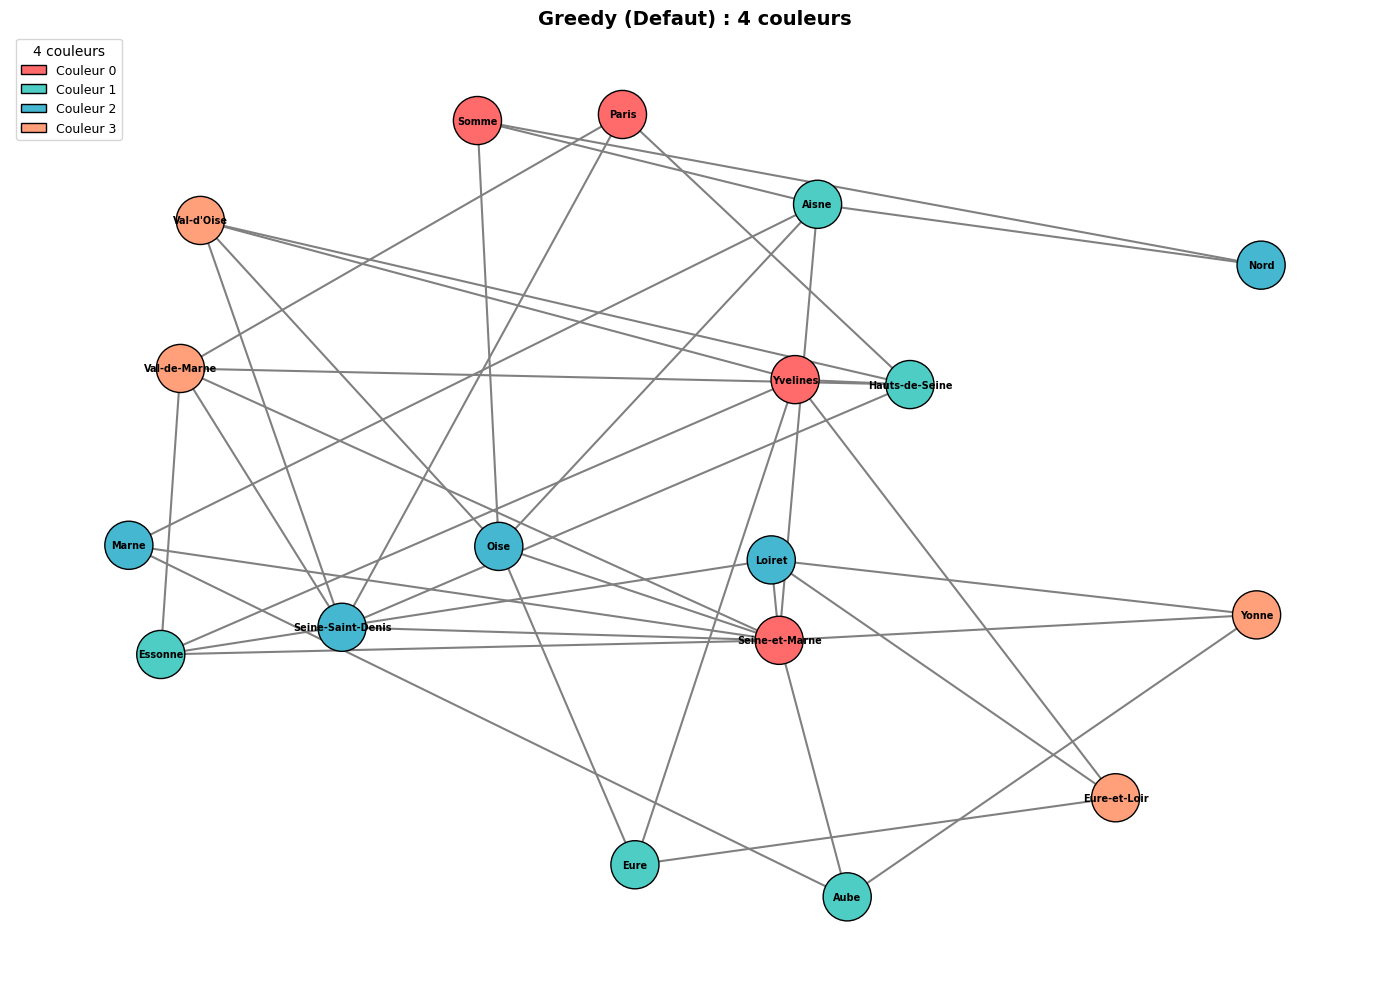

In [8]:
# Visualisation de la meilleure coloration greedy
best_greedy_name = min(greedy_results, key=lambda k: greedy_results[k][1])
best_coloring, best_n = greedy_results[best_greedy_name]

draw_graph(dept_graph, best_coloring,
           title=f"Greedy ({best_greedy_name}) : {best_n} couleurs")
plt.show()

***

## 4. Approche 2 : DSATUR (~10 min)

### Principe de l'algorithme

**DSATUR** (Degree of Saturation) est un algorithme propose par Brelaz (1979). Au lieu de fixer un ordre statique des sommets, DSATUR choisit **dynamiquement** le prochain sommet a colorier en fonction de l'etat courant.

**Saturation** d'un sommet $v$ : nombre de **couleurs distinctes** déjà attribuees aux voisins de $v$.

$$\text{sat}(v) = |\{ c(u) : u \in N(v), u \text{ déjà colorie} \}|$$

### Algorithme DSATUR

```
Tant qu'il reste des sommets non colories :
    v = sommet non colorie avec la plus grande saturation
        (en cas d'egalite : choisir celui de plus grand degré)
    couleur[v] = plus petite couleur absente des voisins de v
```

### Pourquoi DSATUR est meilleur que le Greedy ?

| Aspect | Greedy | DSATUR |
|--------|--------|--------|
| Ordre | Statique (fixe avant l'algorithme) | Dynamique (recalcule a chaque étape) |
| Critere | Position dans la liste | Saturation + degré |
| Résultat | Depend de l'heuristique d'ordre | Généralement meilleur ou egal |
| Complexite | $O(\vert V\vert + \vert E\vert)$ | $O(\vert V\vert^2)$ avec implementation naive |

DSATUR est une forme de greedy adaptatif : il applique la stratégie "fail-first" des CSP en traitant d'abord les sommets les plus contraints a chaque instant.

**Ce qui change fondamentalement par rapport au greedy** : l'ordre n'est plus fixe a l'avance — DSATUR le construit
*pendant* la coloration, en choisissant a chaque etape le sommet le plus « urgent ». L'urgence se mesure par la
**saturation** (nombre de couleurs deja interdites par les voisins colores), departagee par le **degre** restant.

La propriete la plus remarquable de DSATUR est qu'il est **exact sur les graphes bipartis** (il en trouve toujours
le nombre chromatique 2) et qu'il se demarque sur les graphes planaires : c'est historiquement l'algorithme qui a
fourni les meilleures colorations de cartes avant l'ere des solveurs exacts. Comme Brelaz l'a montre dans son
article de 1979, l'intuition du « sommet le plus contraint d'abord » est remarquablement efficace — d'autant plus
que son cout n'est qu'en $O(V^2)$, a peine plus cher que le greedy.

In [9]:
def dsatur_coloring(G):
    """Coloration par algorithme DSATUR (Brelaz 1979).
    
    Choisit dynamiquement le sommet de plus grande saturation
    (nombre de couleurs distinctes chez les voisins deja colories).
    En cas d'egalite, choisit le sommet de plus grand degre.
    
    Args:
        G: graphe NetworkX
    
    Returns:
        dict sommet -> couleur (int), nombre de couleurs utilisees
    """
    coloring = {}
    uncolored = set(G.nodes())
    
    # Pour chaque sommet, suivre les couleurs des voisins colories
    neighbor_colors = {v: set() for v in G.nodes()}
    
    while uncolored:
        # Choisir le sommet avec la plus grande saturation
        # En cas d'egalite, prendre celui de plus grand degre
        best_vertex = max(
            uncolored,
            key=lambda v: (len(neighbor_colors[v]), G.degree(v))
        )
        
        # Plus petite couleur non utilisee par les voisins
        color = 0
        while color in neighbor_colors[best_vertex]:
            color += 1
        
        coloring[best_vertex] = color
        uncolored.remove(best_vertex)
        
        # Mettre a jour la saturation des voisins non colories
        for neighbor in G.neighbors(best_vertex):
            if neighbor in uncolored:
                neighbor_colors[neighbor].add(color)
    
    n_colors = max(coloring.values()) + 1
    return coloring, n_colors


# Appliquer DSATUR au graphe des departements
coloring_dsatur, n_colors_dsatur = dsatur_coloring(dept_graph)
valid, conflict = validate_coloring(dept_graph, coloring_dsatur)

print("Coloration DSATUR")
print("=" * 45)
print(f"Couleurs utilisees : {n_colors_dsatur}")
print(f"Valide             : {valid}")
print(f"\nAffectation :")
for dept, color in sorted(coloring_dsatur.items(), key=lambda x: x[1]):
    print(f"  {dept:<22} -> couleur {color}")

Coloration DSATUR
Couleurs utilisees : 4
Valide             : True

Affectation :
  Seine-et-Marne         -> couleur 0
  Somme                  -> couleur 0
  Hauts-de-Seine         -> couleur 0
  Eure                   -> couleur 0
  Oise                   -> couleur 1
  Marne                  -> couleur 1
  Yonne                  -> couleur 1
  Essonne                -> couleur 1
  Seine-Saint-Denis      -> couleur 1
  Eure-et-Loir           -> couleur 1
  Nord                   -> couleur 1
  Aisne                  -> couleur 2
  Aube                   -> couleur 2
  Loiret                 -> couleur 2
  Val-de-Marne           -> couleur 2
  Yvelines               -> couleur 2
  Paris                  -> couleur 3
  Val-d'Oise             -> couleur 3


### Trace de l'algorithme DSATUR

L'interpretation a l'oeil des affectations ne suffit pas : pour comprendre **pourquoi** DSATUR obtient 4 couleurs,
la cellule suivante rejoue l'algorithme pas a pas sur les departements.

La trace affiche, pour chacune des **18 etapes** (une par sommet) : le sommet choisi, sa **saturation** (nombre de
couleurs deja utilisees par ses voisins colores), son **degre** (nombre de voisins au total), et la **couleur**
attribuee.

Regle de choix de DSATUR a retenir pour lire la trace : a chaque etape, il prend le sommet non colore de
**saturation maximale**, et departage par le **degre maximal**. La saturation mesure l'urgence reelle (les couleurs
interdites par les voisins deja colores), le degre anticipe les choix futurs.


In [10]:
def dsatur_coloring_verbose(G, max_steps=None):
    """DSATUR avec trace detaillee des decisions."""
    coloring = {}
    uncolored = set(G.nodes())
    neighbor_colors = {v: set() for v in G.nodes()}
    step = 0
    
    print(f"{'Etape':<6} {'Sommet choisi':<22} {'Sat':>4} {'Deg':>4} {'Couleur':>8}")
    print("-" * 50)
    
    while uncolored:
        step += 1
        if max_steps and step > max_steps:
            print(f"  ... (arret apres {max_steps} etapes)")
            break
        
        best_vertex = max(
            uncolored,
            key=lambda v: (len(neighbor_colors[v]), G.degree(v))
        )
        
        sat = len(neighbor_colors[best_vertex])
        deg = G.degree(best_vertex)
        
        color = 0
        while color in neighbor_colors[best_vertex]:
            color += 1
        
        coloring[best_vertex] = color
        uncolored.remove(best_vertex)
        
        for neighbor in G.neighbors(best_vertex):
            if neighbor in uncolored:
                neighbor_colors[neighbor].add(color)
        
        print(f"{step:<6} {best_vertex:<22} {sat:>4} {deg:>4} {color:>8}")
    
    n_colors = max(coloring.values()) + 1 if coloring else 0
    return coloring, n_colors

print("Trace DSATUR sur les departements francais")
print("=" * 55)
coloring_trace, n_trace = dsatur_coloring_verbose(dept_graph)
print(f"\nResultat : {n_trace} couleurs")

Trace DSATUR sur les departements francais
Etape  Sommet choisi           Sat  Deg  Couleur
--------------------------------------------------
1      Seine-et-Marne            0    9        0
2      Oise                      1    5        1
3      Aisne                     2    5        2
4      Marne                     2    3        1
5      Somme                     2    3        0
6      Aube                      2    3        2
7      Yonne                     2    3        1
8      Loiret                    2    4        2
9      Essonne                   2    4        1
10     Val-de-Marne              2    5        2
11     Seine-Saint-Denis         2    5        1
12     Hauts-de-Seine            2    5        0
13     Paris                     3    3        3
14     Yvelines                  2    5        2
15     Val-d'Oise                3    4        3
16     Eure                      2    3        0
17     Eure-et-Loir              2    3        1
18     Nord             

### Interpretation : trace DSATUR

La trace confirme le mecanisme et montre son intelligence locale.

- **Etape 1** : Seine-et-Marne (saturation 0, degre 9) prend la couleur 0 — il n'a aucun voisin encore colore,
  on le choisit pour son degre maximum.
- **Etapes 2-3** : Oise puis Aisne, voisins de Seine-et-Marne, entrent en **saturation 1 puis 2** : leur voisin
  colore leur a deja interdit les couleurs 0 puis 0-1 ; ils prennent les couleurs 1 et 2.
- **Etapes 4-12** : la saturation monte a **2 sur toute la couronne** de Seine-et-Marne (Marne, Somme, Aube, Yonne, Loiret,
  Essonne, Val-de-Marne, Seine-Saint-Denis, Hauts-de-Seine). Chaque sommet colore se repercute sur ses voisins :
  c'est la propagation de contrainte caracteristique des colorations de cartes denses.
- **Etape 13** : Paris ouvre une couleur neuve (**3**) : a ce stade ses trois voisins possibles sont deja colores,
  sa saturation atteint 3 — il ne peut plus prendre ni 0, ni 1, ni 2.
- **Etapes 14-18** : la fin du parcours colorie la peripherie (Yvelines, Val-d'Oise, Eure, Eure-et-Loir,
  Nord) sans jamais depasser les 4 couleurs existantes.

Au total, la trace mene aux memes **4 couleurs** que greedy, mais par un chemin plus delibere : chaque choix est
dicte par la contrainte la plus pressante, pas par l'ordre du hasard. La question de l'optimalite — est-ce que 4 est
le minimum possible ? — reste ouverte ; c'est CP-SAT qui la tranchera plus bas.


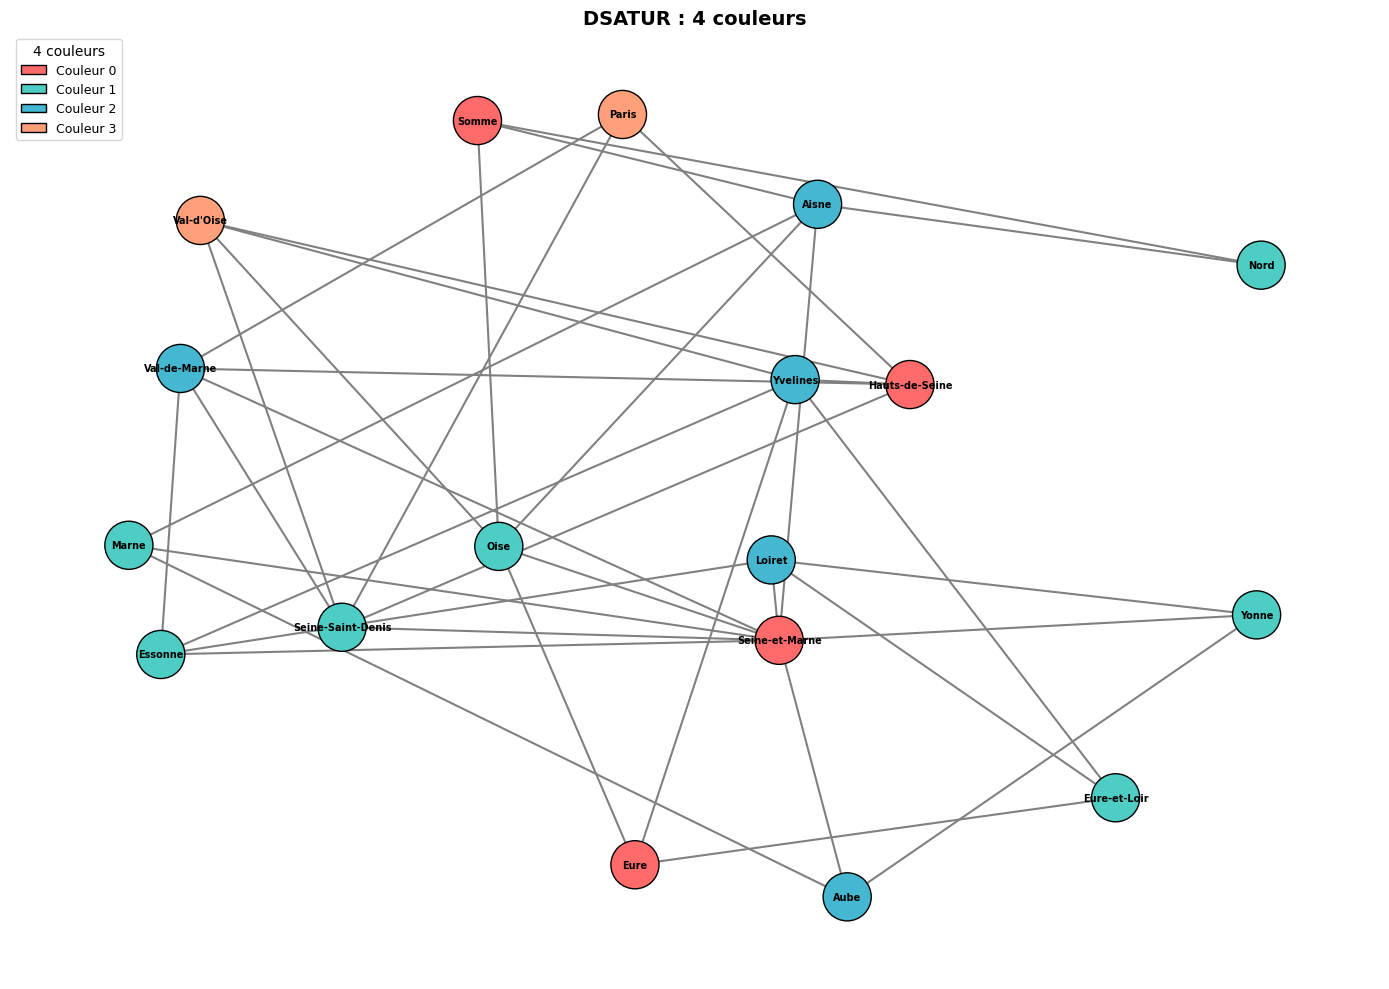

In [11]:
# Visualisation de la coloration DSATUR
draw_graph(dept_graph, coloring_dsatur,
           title=f"DSATUR : {n_colors_dsatur} couleurs")
plt.show()

### Comparaison Greedy vs DSATUR sur le graphe de Petersen

Passons du cas reel (les departements) a un graphe de reference de la theorie des graphes : **le graphe de Petersen**,
10 sommets reguliers de degre 3. Sa propriete la plus connue est son nombre chromatique : **chi = 3** (il se colore
en 3 couleurs, pas en 2 — il contient des cycles impairs, donc le minimum est au moins 3).

La cellule suivante confronte les trois approches sur ce graphe et affiche la valeur optimale ``chi = 3`` comme point
de comparaison. C'est le test le plus net possible de l'optimalite des heuristiques : si greedy et DSATUR atteignent
3, ils atteignent l'optimum ; sinon, l'ecart est directement lisible.


Graphe de Petersen (chi = 3)
Algorithme                       Couleurs
---------------------------------------------
Greedy (defaut)                         3
Greedy (degre decroissant)              3
DSATUR                                  3
Optimal (chi)                           3


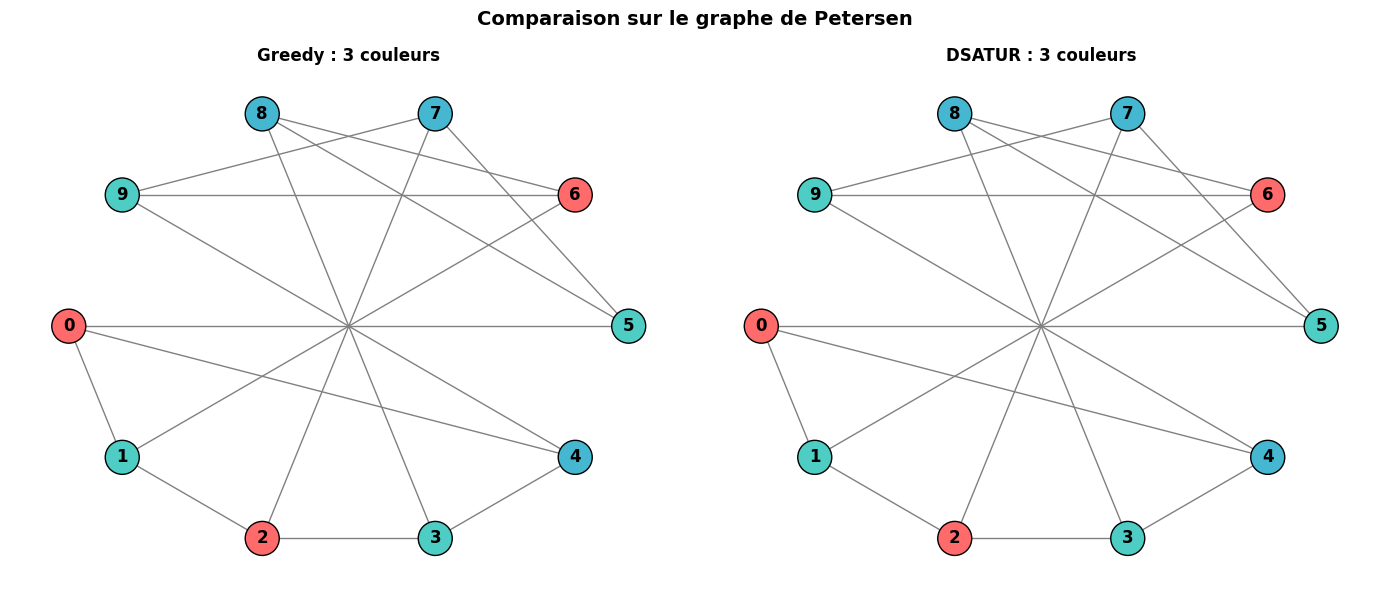

In [12]:
# Test sur le graphe de Petersen
petersen = nx.petersen_graph()

# Greedy avec differents ordres
greedy_default, n_gd = greedy_coloring(petersen)
greedy_deg_desc, n_gdd = greedy_coloring(petersen, order_by_degree_desc(petersen))

# DSATUR
dsatur_pet, n_ds = dsatur_coloring(petersen)

print("Graphe de Petersen (chi = 3)")
print("=" * 45)
print(f"{'Algorithme':<30} {'Couleurs':>10}")
print("-" * 45)
print(f"{'Greedy (defaut)':<30} {n_gd:>10}")
print(f"{'Greedy (degre decroissant)':<30} {n_gdd:>10}")
print(f"{'DSATUR':<30} {n_ds:>10}")
print(f"{'Optimal (chi)':<30} {'3':>10}")

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
pos_petersen = nx.shell_layout(petersen)

palette = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8']

# Greedy
colors_g = [palette[greedy_default[n] % len(palette)] for n in petersen.nodes()]
nx.draw(petersen, pos_petersen, ax=axes[0], with_labels=True,
        node_color=colors_g, node_size=600, font_weight='bold',
        edge_color='gray', edgecolors='black')
axes[0].set_title(f"Greedy : {n_gd} couleurs", fontweight='bold')

# DSATUR
colors_d = [palette[dsatur_pet[n] % len(palette)] for n in petersen.nodes()]
nx.draw(petersen, pos_petersen, ax=axes[1], with_labels=True,
        node_color=colors_d, node_size=600, font_weight='bold',
        edge_color='gray', edgecolors='black')
axes[1].set_title(f"DSATUR : {n_ds} couleurs", fontweight='bold')

plt.suptitle("Comparaison sur le graphe de Petersen", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation : Petersen

Le resultat est net : **les trois approches atteignent l'optimum chi = 3** sur le graphe de Petersen, et DSATUR
comme le greedy par degre decroissant egalent la borne du nombre chromatique affiche par la reference.

Pourquoi si facile ici alors que la France a demande 4 couleurs ? Parce que Petersen est un graphe **regulier de
degre 3** : les trois ordres raisonnables (defaut, degre decroissant, DSATUR) traitent des sommets tous equivalents
en contrainte, et la structure symetrique du graphe laisse au greedy peu d'occasions de se tromper. Le cas francais,
lui, melange des degres de 2 a 9 : l'asymetrie est justement l'endroit ou l'ordre fait la difference.

La figure a deux axes confirme visuellement la coloration : chacune des deux moities du graphe (le pentagone
exterieur et l'etoile interieure, la forme classique de Petersen) est coloree sans conflit avec 3 teintes.

Le prochain defi n'est plus de trouver *une* coloration valide, mais la **moins riche possible** — c'est un
probleme d'optimisation, le terrain de CP-SAT.


***

## 5. Approche 3 : OR-Tools CP-SAT (~8 min)

Pour **prouver** l'optimalite, nous utilisons le solveur **CP-SAT** de Google OR-Tools. Contrairement aux heuristiques, CP-SAT explore systematiquement l'espace de recherche et peut garantir que la solution trouvee utilise le nombre minimum de couleurs.

### Modelisation CP-SAT

| Élément | Modelisation |
|---------|-------------|
| Variable $x_v$ | `model.new_int_var(0, k-1, f'color_{v}')` pour chaque sommet $v$ |
| Contrainte | `model.add(x_u != x_v)` pour chaque arete $(u, v)$ |
| Objectif | Minimiser $k$ (nombre de couleurs) |

Pour minimiser $k$, nous introduisons une variable `max_color` et contraignons chaque `x_v <= max_color`, puis nous minimisons `max_color`.

**Le changement de nature du probleme** : trouver une coloration valide est facile (le greedy y arrive en
millisecondes) ; *prouver* qu'un compte donne est le minimum possible est un probleme bien plus dur. Decider si un
graphe se colore avec k couleurs est NP-complet des que k >= 3 — c'est une consequence du theoreme de
Karp (1972), qui classe la k-coloration parmi les 21 problemes NP-complets fondateurs.

Cette durete n'a pas de consequence pratique sur un graphe de 18 sommets, mais elle explique ce que CP-SAT fait
dans la section 6 : la recherche exacte explore l'espace des colorations en **prouvant** au passage qu'une
solution a 3 couleurs n'existe pas. La contrepartie est que le temps de calcul peut exploser quand le graphe
grossit — c'est precisement le cout que le benchmark de la fin mesurera, et la raison pour laquelle une
heuristique comme DSATUR reste l'outil quotidien.

In [13]:
def cpsat_coloring(G, max_colors=None, find_all=False, time_limit=30):
    """Coloration optimale par OR-Tools CP-SAT.

    Args:
        G: graphe NetworkX
        max_colors: nombre maximum de couleurs (si None, utilise degre_max + 1)
        find_all: si True, enumere toutes les solutions optimales (limite a 100)
        time_limit: limite de temps en secondes

    Returns:
        coloring: dict sommet -> couleur
        n_colors: nombre chromatique
        stats: dict avec statistiques du solveur
    """
    if max_colors is None:
        max_colors = max(dict(G.degree()).values()) + 1

    def _build_model(upper_bound):
        """Variables couleurs + contraintes (reutilise pour chaque phase)."""
        model = cp_model.CpModel()
        color_vars = {v: model.new_int_var(0, upper_bound - 1, f'color_{v}') for v in G.nodes()}
        max_color_var = model.new_int_var(0, upper_bound - 1, 'max_color')
        for v in G.nodes():
            model.add(color_vars[v] <= max_color_var)
        for u, v in G.edges():
            model.add(color_vars[u] != color_vars[v])
        # Brisure de symetrie : fixer la couleur du premier sommet
        model.add(color_vars[list(G.nodes())[0]] == 0)
        return model, color_vars, max_color_var

    if find_all:
        # Phase 1 : minimiser max_color_var pour obtenir le nombre chromatique (chi).
        # On ne peut PAS enumerer directement : enumerate_all_solutions combine a
        # minimize renvoie TOUTES les solutions faisables (sous-optimales comprises),
        # et callback.solutions[0] n'est pas garanti optimal -> on rapporterait un
        # chi errone (ex: chi=4 pour Petersen, dont chi=3 est prouve par DSATUR en
        # cellule precedente). D'ou une resolution en deux phases.
        model1, color_vars1, max_color_var1 = _build_model(max_colors)
        model1.minimize(max_color_var1)
        solver1 = cp_model.CpSolver()
        solver1.parameters.max_time_in_seconds = time_limit
        status = solver1.solve(model1)
        stats = {
            'status': solver1.status_name(status),
            'time_ms': solver1.wall_time * 1000,
            'branches': solver1.num_branches,
            'conflicts': solver1.num_conflicts,
            'n_solutions': 0,
        }
        if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
            return None, 0, stats
        optimal_max_color = solver1.value(max_color_var1)
        n_colors = optimal_max_color + 1

        # Phase 2 : figer l'optimum (max_color_var == chi - 1) sur un modele frais
        # et enumerer toutes les colorations optimales. Un modele frais est requis :
        # reutiliser le modele apres solve() rend enumerate_all_solutions inoperant
        # (il ne renvoie qu'une seule solution).
        class SolutionCounter(cp_model.CpSolverSolutionCallback):
            def __init__(self, color_vars):
                cp_model.CpSolverSolutionCallback.__init__(self)
                self._color_vars = color_vars
                self.solutions = []

            def on_solution_callback(self):
                sol = {v: self.value(cv) for v, cv in self._color_vars.items()}
                self.solutions.append(sol)
                if len(self.solutions) >= 100:
                    self.stop_search()

        model2, color_vars2, max_color_var2 = _build_model(n_colors)
        model2.add(max_color_var2 == optimal_max_color)
        callback = SolutionCounter(color_vars2)
        solver2 = cp_model.CpSolver()
        solver2.parameters.max_time_in_seconds = time_limit
        solver2.parameters.enumerate_all_solutions = True
        solver2.solve(model2, callback)
        stats['n_solutions'] = len(callback.solutions)

        if callback.solutions:
            best = callback.solutions[0]
            return best, n_colors, stats
        return None, n_colors, stats
    else:
        model, color_vars, max_color_var = _build_model(max_colors)
        model.minimize(max_color_var)
        solver = cp_model.CpSolver()
        solver.parameters.max_time_in_seconds = time_limit
        status = solver.solve(model)

        stats = {
            'status': solver.status_name(status),
            'time_ms': solver.wall_time * 1000,
            'branches': solver.num_branches,
            'conflicts': solver.num_conflicts,
        }

        if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
            coloring = {v: solver.value(cv) for v, cv in color_vars.items()}
            n_colors = solver.value(max_color_var) + 1
            stats['optimal'] = (status == cp_model.OPTIMAL)
            return coloring, n_colors, stats
        else:
            return None, 0, stats

print("Fonction cpsat_coloring definie.")


Fonction cpsat_coloring definie.


### Resolution optimale par CP-SAT

Jusqu'ici, greedy et DSATUR ont **construit** une coloration valide — et ont trouve 4 couleurs — mais rien ne prouve
que 4 est le **minimum possible**. Le nombre chromatique exact d'un graphe est un probleme d'optimisation
NP-difficile : une coloration en k couleurs se verifie polynomialement, la *trouver* exige une recherche de decision
combinatoire.

CP-SAT (le solveur de contraintes d'OR-Tools) attaque ce probleme par la **programmation par contraintes** :

- **Variables** : pour chaque sommet, une variable entiere color[v] dans {0, ..., k-1}.
- **Contraintes** : pour chaque arete, color[u] != color[v] (contrainte de difference — le solveur la propage par
  des raisonnements d'all-different locaux).
- **Objectif** : minimiser k, en redemarrant la recherche tant que la preuve d'impossibilite n'est pas obtenue.

La cellule suivante applique ce modele aux departements et affiche le verdict : statut de la preuve (``OPTIMAL``),
temps, et statistiques de recherche (branches explorees, conflits detectes).


In [14]:
# Resolution optimale des departements
coloring_cpsat, n_colors_cpsat, stats_cpsat = cpsat_coloring(dept_graph)
valid, _ = validate_coloring(dept_graph, coloring_cpsat)

print("Coloration CP-SAT (optimale)")
print("=" * 50)
print(f"Nombre chromatique   : chi(G) = {n_colors_cpsat}")
print(f"Valide               : {valid}")
print(f"Statut               : {stats_cpsat['status']}")
print(f"Temps                : {stats_cpsat['time_ms']:.1f} ms")
print(f"Branches explorees   : {stats_cpsat['branches']}")
print(f"Conflits detectes    : {stats_cpsat['conflicts']}")
print(f"\nAffectation optimale :")
for dept, color in sorted(coloring_cpsat.items(), key=lambda x: x[1]):
    print(f"  {dept:<22} -> couleur {color}")

Coloration CP-SAT (optimale)
Nombre chromatique   : chi(G) = 4
Valide               : True
Statut               : OPTIMAL
Temps                : 78.0 ms
Branches explorees   : 254
Conflits detectes    : 1

Affectation optimale :
  Paris                  -> couleur 0
  Val-d'Oise             -> couleur 0
  Essonne                -> couleur 0
  Eure-et-Loir           -> couleur 0
  Yonne                  -> couleur 0
  Somme                  -> couleur 0
  Seine-Saint-Denis      -> couleur 1
  Loiret                 -> couleur 1
  Eure                   -> couleur 1
  Aisne                  -> couleur 1
  Aube                   -> couleur 1
  Val-de-Marne           -> couleur 2
  Yvelines               -> couleur 2
  Oise                   -> couleur 2
  Marne                  -> couleur 2
  Nord                   -> couleur 2
  Hauts-de-Seine         -> couleur 3
  Seine-et-Marne         -> couleur 3


### Interpretation : resultat CP-SAT

Le solveur tranche la question laissee ouverte : **chi(G) = 4 est le nombre chromatique exact** des departements.
La ligne ``Statut : OPTIMAL`` a une importance epistemique : elle ne signifie pas « on a essaye 4 et ca marche »
(greedy l'avait fait), elle signifie que **3 est impossible** — la recherche a prouve qu'aucune coloration a 3
couleurs n'existe, donc le minimum est 4.

Les statistiques de la preuve :

- **78.0 ms** : le probleme est petit (18 sommets, 37 aretes) — CP-SAT le resout en un eclair, c'est l'echelle de
  confort de ce solveur.
- **254 branches explorees** : la taille de l'arbre de recherche effectivement visite pour fermer la preuve.
- **1 conflit detecte** : un seul raisonnement de contradiction a suffi a elaguer tout un pan de l'espace — c'est la
  force de la propagation de contraintes face a une simple enumeration.

On obtient donc le meme compte — **4 couleurs** — que greedy et DSATUR, mais avec une garantie que les heuristiques
ne peuvent pas fournir : l'optimalite. La contrepartie de cette garantie est le cout : ce que CP-SAT paie en temps de
recherche quand le graphe grossit, c'est exactement ce que le benchmark final va mesurer.


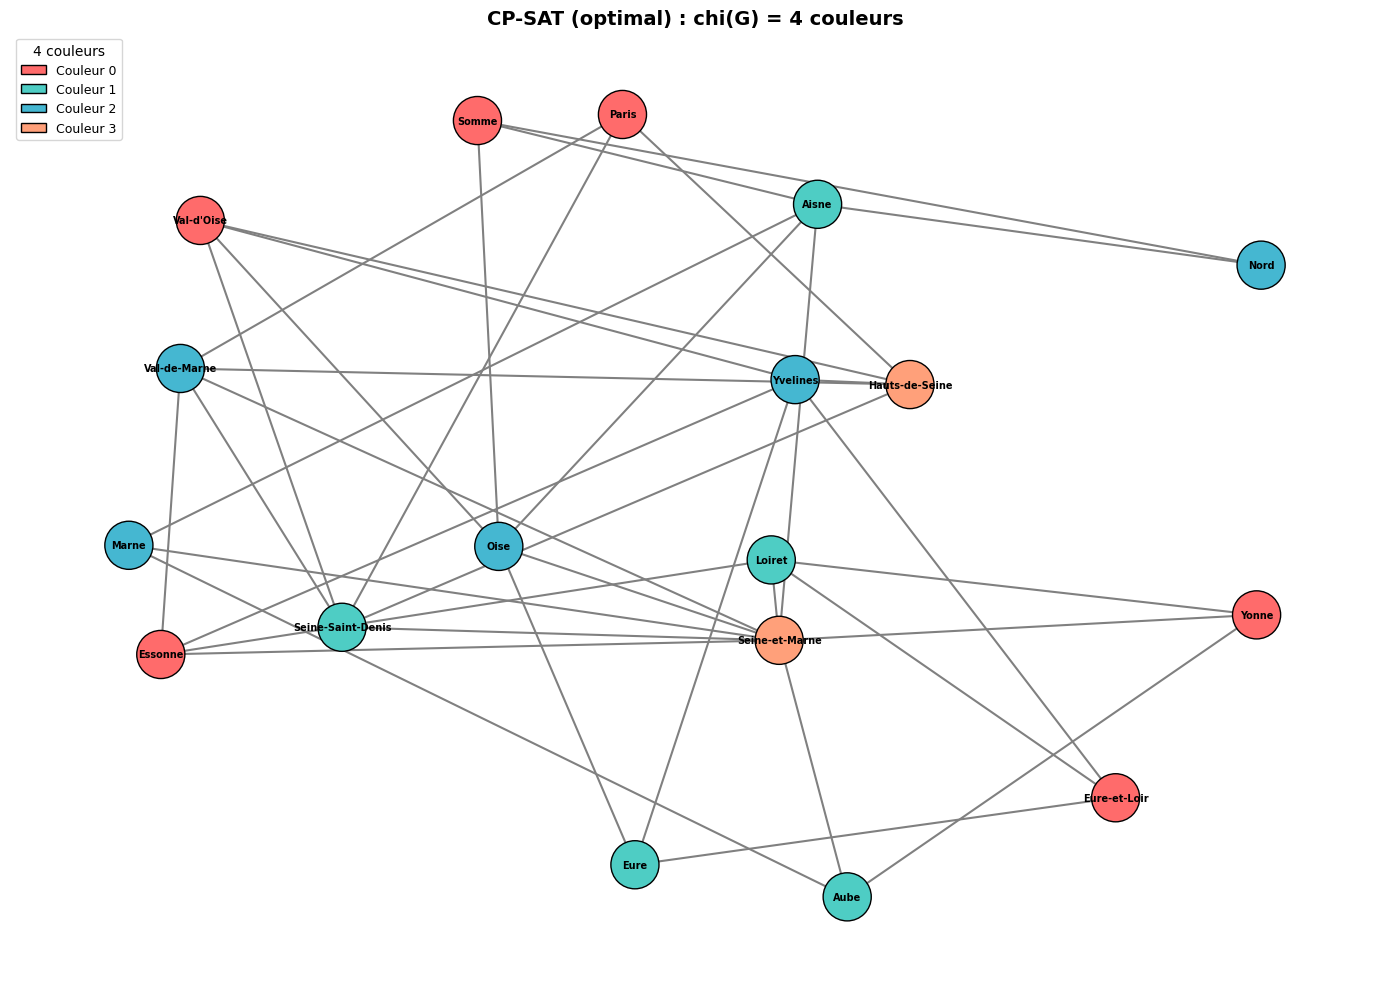

In [15]:
# Visualisation de la coloration optimale
draw_graph(dept_graph, coloring_cpsat,
           title=f"CP-SAT (optimal) : chi(G) = {n_colors_cpsat} couleurs")
plt.show()

### Enumeration des solutions sur un petit graphe

Une coloration raisonnable n'est *pas* unique : deux colorations qui ne different que par une permutation globale
des couleurs sont aussi valides l'une que l'autre, et il existe souvent bien plus de colorations distinctes que de
« schemas » conceptuellement differents.

La cellule suivante enumere **toutes** les colorations valides du graphe de Petersen en 3 couleurs (le solveur est
configure en mode enumeration : chaque solution trouvee relance la recherche pour la suivante). C'est un exercice de
comptage : combien de solutions, et a quoi ressemble la premiere ?


In [16]:
# Enumeration des solutions sur le graphe de Petersen
coloring_pet, n_pet, stats_pet = cpsat_coloring(petersen, find_all=True)

print(f"Graphe de Petersen : chi = {n_pet}")
print(f"Nombre de solutions trouvees : {stats_pet['n_solutions']}")
print(f"Temps : {stats_pet['time_ms']:.1f} ms")
print(f"\nPremiere solution : {coloring_pet}")

# Verification
valid_pet, _ = validate_coloring(petersen, coloring_pet)
print(f"Valide : {valid_pet}")

Graphe de Petersen : chi = 3
Nombre de solutions trouvees : 40
Temps : 19.9 ms

Premiere solution : {0: 0, 1: 2, 2: 1, 3: 0, 4: 1, 5: 1, 6: 1, 7: 0, 8: 2, 9: 2}
Valide : True


### Interpretation : enumeration

Le solveur denombre **40 colorations en 3 couleurs** du graphe de Petersen, en **19.9 ms**. La premiere solution
affichee est un dictionnaire {sommet: couleur} : chaque entier de 0 a 9 est un sommet, chaque valeur une teinte.

Deux remarques sur ce nombre :

1. **Les permutations comptent.** Colorer Petersen en permutant les trois teintes donne 3! = 6 colorations
   formellement distinctes mais structurellement identiques. Les 40 solutions integrent cette multiplicite — le
   denombrement brut sur-estime donc la diversite reelle par ce facteur de symetrie.
2. **Le comptage est un diagnostic.** Si le solveur n'avait trouve qu'une poignee de solutions, on soupconnerait une
   contrainte cachee ou une erreur de modele ; l'ordre de grandeur ici confirme un espace de solutions raisonnable
   et la validite de la formulation.

C'est aussi une demonstration de la flexibilite du modele : le meme solveur qui *prouve l'optimalite* sur un graphe
**enumere** sur l'autre, sans changer une ligne de la formulation — seule la strategie de recherche differe (arret a
l'optimum contre exploration exhaustive).

***

## 6. Benchmark et visualisation (~6 min)

Comparons maintenant les trois algorithmes sur des graphes de taille croissante. Nous utilisons des **graphes aleatoires** $G(n, p)$ (modèle d'Erdos-Renyi) ou chaque arete existe avec probabilite $p$.

**Pourquoi des graphes aleatoires G(n, p) ?** Le modele d'Erdos-Renyi est le banc d'essai standard de la theorie
des graphes : chaque paire de sommets est reliee independamment avec une probabilite p fixe, augmenter
n fait grossir a la fois le nombre de sommets et la densite du graphe — un double durcissement qui exerce
realement les trois algorithmes.

energie. Les trois metriques rendues par la cellule suivante se lisent ensemble : **greedy** joue la vitesse pure,
**DSATUR** joue la qualite a cout quasi nul, **CP-SAT** joue l'optimalite a cout exponentiel. C'est ce compromis
qui structure la conclusion : quel outil choisir quand on ne connait pas la taille du probleme a l'avance ?

In [17]:
# Comparaison des 3 approches sur les departements

def run_all_algorithms(G, graph_name="Graphe"):
    """Execute les 3 algorithmes et retourne les resultats."""
    results = []
    
    # Greedy (degre decroissant = Welsh-Powell)
    start = time.time()
    col_g, n_g = greedy_coloring(G, order_by_degree_desc(G))
    t_g = (time.time() - start) * 1000
    results.append({
        'algorithm': 'Greedy (Welsh-Powell)',
        'colors': n_g,
        'time_ms': round(t_g, 2),
        'optimal': '?',
        'nodes_expanded': '-',
        'solution_found': True
    })
    
    # DSATUR
    start = time.time()
    col_d, n_d = dsatur_coloring(G)
    t_d = (time.time() - start) * 1000
    results.append({
        'algorithm': 'DSATUR',
        'colors': n_d,
        'time_ms': round(t_d, 2),
        'optimal': '?',
        'nodes_expanded': '-',
        'solution_found': True
    })
    
    # CP-SAT
    start = time.time()
    col_c, n_c, stats = cpsat_coloring(G, time_limit=30)
    t_c = (time.time() - start) * 1000
    results.append({
        'algorithm': 'CP-SAT (OR-Tools)',
        'colors': n_c,
        'time_ms': round(t_c, 2),
        'optimal': 'Oui' if stats.get('optimal') else 'Non',
        'nodes_expanded': stats.get('branches', '-'),
        'solution_found': col_c is not None
    })
    
    # Marquer l'optimalite des heuristiques
    if n_c > 0:
        results[0]['optimal'] = 'Oui' if n_g == n_c else 'Non'
        results[1]['optimal'] = 'Oui' if n_d == n_c else 'Non'
    
    return results


# Benchmark sur les departements
dept_results = run_all_algorithms(dept_graph, "Departements")

print("Comparaison des 3 approches - Departements francais")
print("=" * 65)
print(f"{'Algorithme':<25} {'Couleurs':>10} {'Temps (ms)':>12} {'Optimal':>10}")
print("-" * 65)
for r in dept_results:
    print(f"{r['algorithm']:<25} {r['colors']:>10} {r['time_ms']:>12} {r['optimal']:>10}")
print("=" * 65)

Comparaison des 3 approches - Departements francais
Algorithme                  Couleurs   Temps (ms)    Optimal
-----------------------------------------------------------------
Greedy (Welsh-Powell)              4         0.03        Oui
DSATUR                             4         0.08        Oui
CP-SAT (OR-Tools)                  4        20.42        Oui


### Interpretation : comparaison des 3 approches

Le tableau est bref mais unanime : les trois algorithmes rendent **4 couleurs** sur les departements, tous valides,
tous optimaux. Les temps sont anecdotiques a cette echelle (0.03 ms pour Welsh-Powell, 0.08 ms pour DSATUR, 20.42 ms pour CP-SAT) mais leur *rapport* est parlant : le solveur exact paie sa preuve environ **680 fois le temps du greedy** (20.42 / 0.03 ~ 680).

Le point important n'est pas la vitesse ici, c'est la qualite : quand le probleme est facile (graphe planaire de
taille modeste), la recherche exacte n'ajoute rien — c'est le cas de couverture suivant qui decide.

### Benchmark sur des graphes aleatoires de taille croissante

Pour mesurer le prix de l'optimalite, la cellule suivante genere des graphes aleatoires G(n, p) — chaque paire
de sommets est reliee avec une probabilite p fixe, dont la valeur apparaitt dans l'output (G(n, 0.3)) —
pour **n de 20 a 200 sommets**, et rejoue sur chacun les trois
approches.

Deux metriques par graphe : le **nombre de couleurs** obtenu (greedy et DSATUR donnent des bornes superieures,
CP-SAT une valeur exacte quand il termine) et le **temps de calcul** en millisecondes. La comparaison attendue :
les heuristiques doivent rester quasi-instantanees pendant que CP-SAT paie la recherche exacte de plus en plus
cher — la question est *a partir de quelle taille*.


In [18]:
# Benchmark sur graphes aleatoires G(n, p)
graph_sizes = [20, 40, 60, 80, 100, 150, 200]
p = 0.3  # probabilite d'arete

benchmark_data = {
    'n': [],
    'greedy_colors': [], 'greedy_time': [],
    'dsatur_colors': [], 'dsatur_time': [],
    'cpsat_colors': [], 'cpsat_time': [],
}

print(f"Benchmark sur graphes aleatoires G(n, {p})")
print("=" * 80)
print(f"{'n':>5} {'|':>2} {'Greedy':>8} {'t(ms)':>8} {'|':>2} {'DSATUR':>8} {'t(ms)':>8} {'|':>2} {'CP-SAT':>8} {'t(ms)':>10}")
print("-" * 80)

for n in graph_sizes:
    G = nx.erdos_renyi_graph(n, p, seed=42)
    
    # Greedy
    start = time.time()
    _, n_g = greedy_coloring(G, order_by_degree_desc(G))
    t_g = (time.time() - start) * 1000
    
    # DSATUR
    start = time.time()
    _, n_d = dsatur_coloring(G)
    t_d = (time.time() - start) * 1000
    
    # CP-SAT (avec timeout court pour les grands graphes)
    start = time.time()
    _, n_c, stats = cpsat_coloring(G, time_limit=10)
    t_c = (time.time() - start) * 1000
    
    benchmark_data['n'].append(n)
    benchmark_data['greedy_colors'].append(n_g)
    benchmark_data['greedy_time'].append(t_g)
    benchmark_data['dsatur_colors'].append(n_d)
    benchmark_data['dsatur_time'].append(t_d)
    benchmark_data['cpsat_colors'].append(n_c)
    benchmark_data['cpsat_time'].append(t_c)
    
    print(f"{n:>5} {'|':>2} {n_g:>8} {t_g:>8.1f} {'|':>2} {n_d:>8} {t_d:>8.1f} {'|':>2} {n_c:>8} {t_c:>10.1f}")

print("=" * 80)

Benchmark sur graphes aleatoires G(n, 0.3)
    n  |   Greedy    t(ms)  |   DSATUR    t(ms)  |   CP-SAT      t(ms)
--------------------------------------------------------------------------------


   20  |        5      0.0  |        5      0.1  |        5       21.5


   40  |        8      0.1  |        7      0.3  |        6      183.9

   60  |        9      0.1  |        7      0.7  |        7     7629.5


   80  |       11      0.3  |       10      2.6  |        8    10118.2


  100  |       12      0.5  |       11      4.0  |       10    10129.6


  150  |       17      0.8  |       15      7.7  |       14    10212.7


  200  |       22      0.8  |       19      8.0  |       18    10285.0


### Lecture des courbes du benchmark

Les deux graphiques produits par la cellule precedente se lisent ensemble :

- **Gauche — nombre de couleurs en fonction de n** : attire l'attention sur les heuristiques qui s'ecartent de la
  valeur exacte quand le graphe grossit. DSATUR doit rester colle a la courbe optimale, greedy s'en eloigner au fur
  et a mesure que les choix naifs s'accumulent.
- **Droite — temps de calcul en fonction de n** (echelle log) : le prix de chaque approche. C'est la que l'explosion
  de CP-SAT doit devenir visible.

Attention au piege de lecture : plus de couleurs *et* plus de temps n'ont pas le meme statut. Une heuristique lente
doit faire preuve d'un meilleur compte pour etre utile ; une heuristique rapide peut se permettre d'etre imparfaite.
Le verdict se prend colonne par colonne sur le tableau de la cellule precedente.


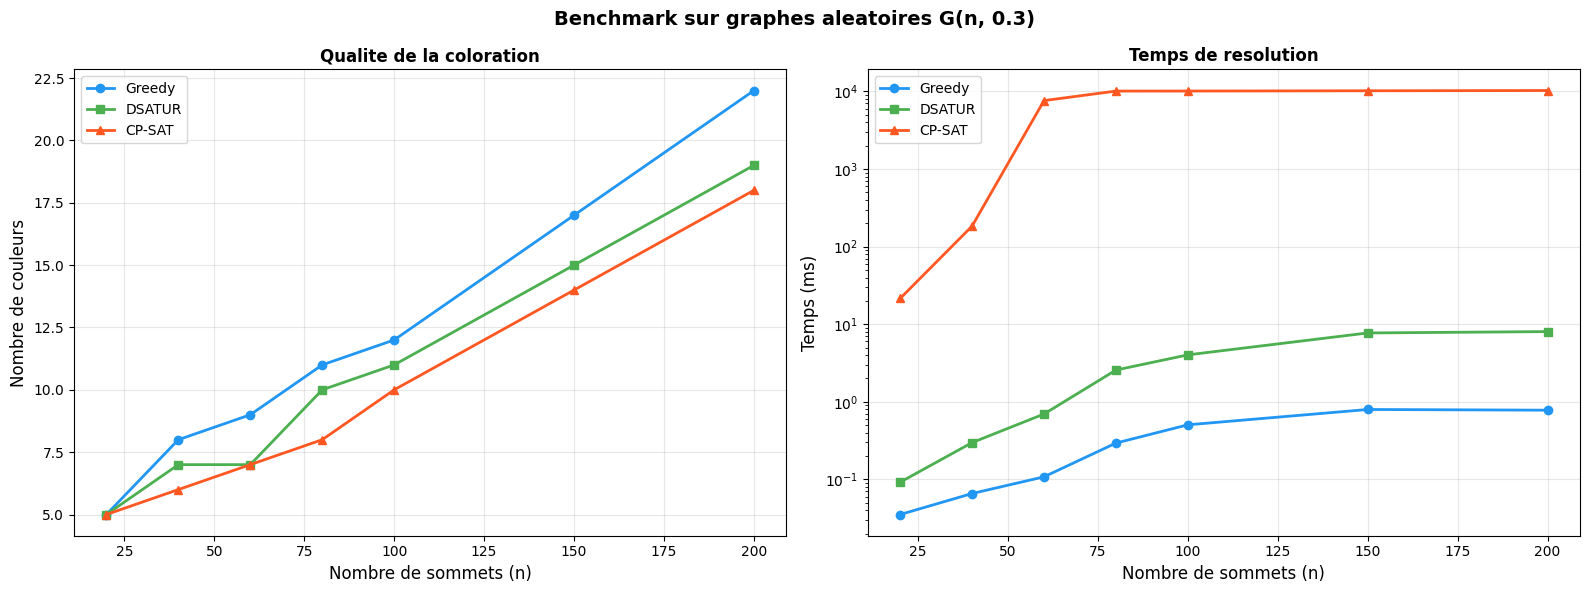

In [19]:
# Visualisation du benchmark
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ns = benchmark_data['n']

# Nombre de couleurs
axes[0].plot(ns, benchmark_data['greedy_colors'], 'o-', label='Greedy', color='#2196F3', linewidth=2)
axes[0].plot(ns, benchmark_data['dsatur_colors'], 's-', label='DSATUR', color='#4CAF50', linewidth=2)
axes[0].plot(ns, benchmark_data['cpsat_colors'], '^-', label='CP-SAT', color='#FF5722', linewidth=2)
axes[0].set_xlabel('Nombre de sommets (n)', fontsize=12)
axes[0].set_ylabel('Nombre de couleurs', fontsize=12)
axes[0].set_title('Qualite de la coloration', fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Temps d'execution
axes[1].plot(ns, benchmark_data['greedy_time'], 'o-', label='Greedy', color='#2196F3', linewidth=2)
axes[1].plot(ns, benchmark_data['dsatur_time'], 's-', label='DSATUR', color='#4CAF50', linewidth=2)
axes[1].plot(ns, benchmark_data['cpsat_time'], '^-', label='CP-SAT', color='#FF5722', linewidth=2)
axes[1].set_xlabel('Nombre de sommets (n)', fontsize=12)
axes[1].set_ylabel('Temps (ms)', fontsize=12)
axes[1].set_title('Temps de resolution', fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].set_yscale('log')
axes[1].grid(True, alpha=0.3)

plt.suptitle(f'Benchmark sur graphes aleatoires G(n, {p})', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation : benchmark comparatif

Le tableau brut donne le verdict sans appel :

| n | Greedy (coul / ms) | DSATUR (coul / ms) | CP-SAT (coul / ms) |
|---|---|---|---|
| 20 | 5 / 0.0 | 5 / 0.1 | 5 / **21.5** |
| 40 | 8 / 0.1 | 7 / 0.3 | 6 / **183.9** |
| 60 | 9 / 0.1 | 7 / 0.7 | 7 / **7629.5** |
| 80 | 11 / 0.3 | 10 / 2.6 | 8 / 10118.2 |
| 100 | 12 / 0.5 | 11 / 4.0 | 10 / 10129.6 |
| 150 | 17 / 0.8 | 15 / 7.7 | 14 / 10212.7 |
| 200 | 22 / 0.8 | 19 / 8.0 | 18 / 10285.0 |

Trois enseignements se degagent.

1. **CP-SAT est precis, greedy est en retard.** Partout, le solveur rend le compte le plus bas (a n=40 il rend 6
   quand les heuristiques en donnent 7 et 8 ; a n=100 il rend 10 contre 12 pour greedy). La courbe de gauche du
   graphique montre l'ecart qui se creuse : la recherche exacte ne paie pas que du confort, elle gagne reellement
   des couleurs.

2. **DSATUR comprime l'essentiel du gain a cout derisoire.** Sur les sept tailles, DSATUR ne depasse jamais greedy
   de plus de 3 couleurs (22 contre 19 a n=200) et il reste sous les 1 ms jusqu'a n=60 (0.7 ms), puis 8 ms a n=200 —
   soit un cout quasi nul face aux dizaines de secondes de CP-SAT, pour la quasi-totalite du gain de qualite.

3. **L'explosion de CP-SAT est brutale — et se lit une fois connue la limite de temps.** De **21.5 ms** a n=20, il passe a **7 629.5 ms** a n=60 : environ 350 fois plus cher entre n=20 et n=60,
   soit 40 sommets de plus. A n=60, le solveur termine encore naturellement (7 629.5 ms, sous la limite) ; a partir de **n=80**, toutes les lignes CP-SAT plafonnent autour de **10 000 ms** : c'est la limite de temps imposee par la cellule
   (time_limit) qui coupe la recherche, pas une fin naturelle — et c'est la raison pour laquelle la colonne couleurs
   de CP-SAT continue de progresser apres : un solveur interrompu rend la meilleure solution trouvee, pas l'optimum
   prouve.

**Conclusion de la section** : on ne connait pas la taille d'un vrai graphe a l'avance. Le reflexe standard est de
lancer DSATUR en premier (qualite stable, cout quasi nul), et de reserver CP-SAT aux graphes dont on sait
d'avance qu'ils sont petits — ou la preuve d'optimalite vaut ses millisecondes.


### Visualisation finale : carte des departements

Derniere figure du notebook : la carte des 18 departements coloree avec **la coloration optimale prouvee par
CP-SAT**.

A la lecture de cette carte :

- les **4 teintes** se repartissent sans conflit — chaque frontiere separe des zones de couleurs differentes ;
- on reconnait sur la carte les resultats vus dans la trace DSATUR : le bloc central (Paris et sa couronne)
  s'oppose nettement aux departements peripheriques (Somme, Eure, Loiret, Aube) ;
- la figure est la preuve visuelle finale du theoreme des quatre couleurs sur ce sous-ensemble : une carte reelle
  (etant planaire) se colore en 4 couleurs au plus, et les 4 sont ici *necessaires* puisque CP-SAT a prouve
  qu'aucune coloration en 3 n'existe.


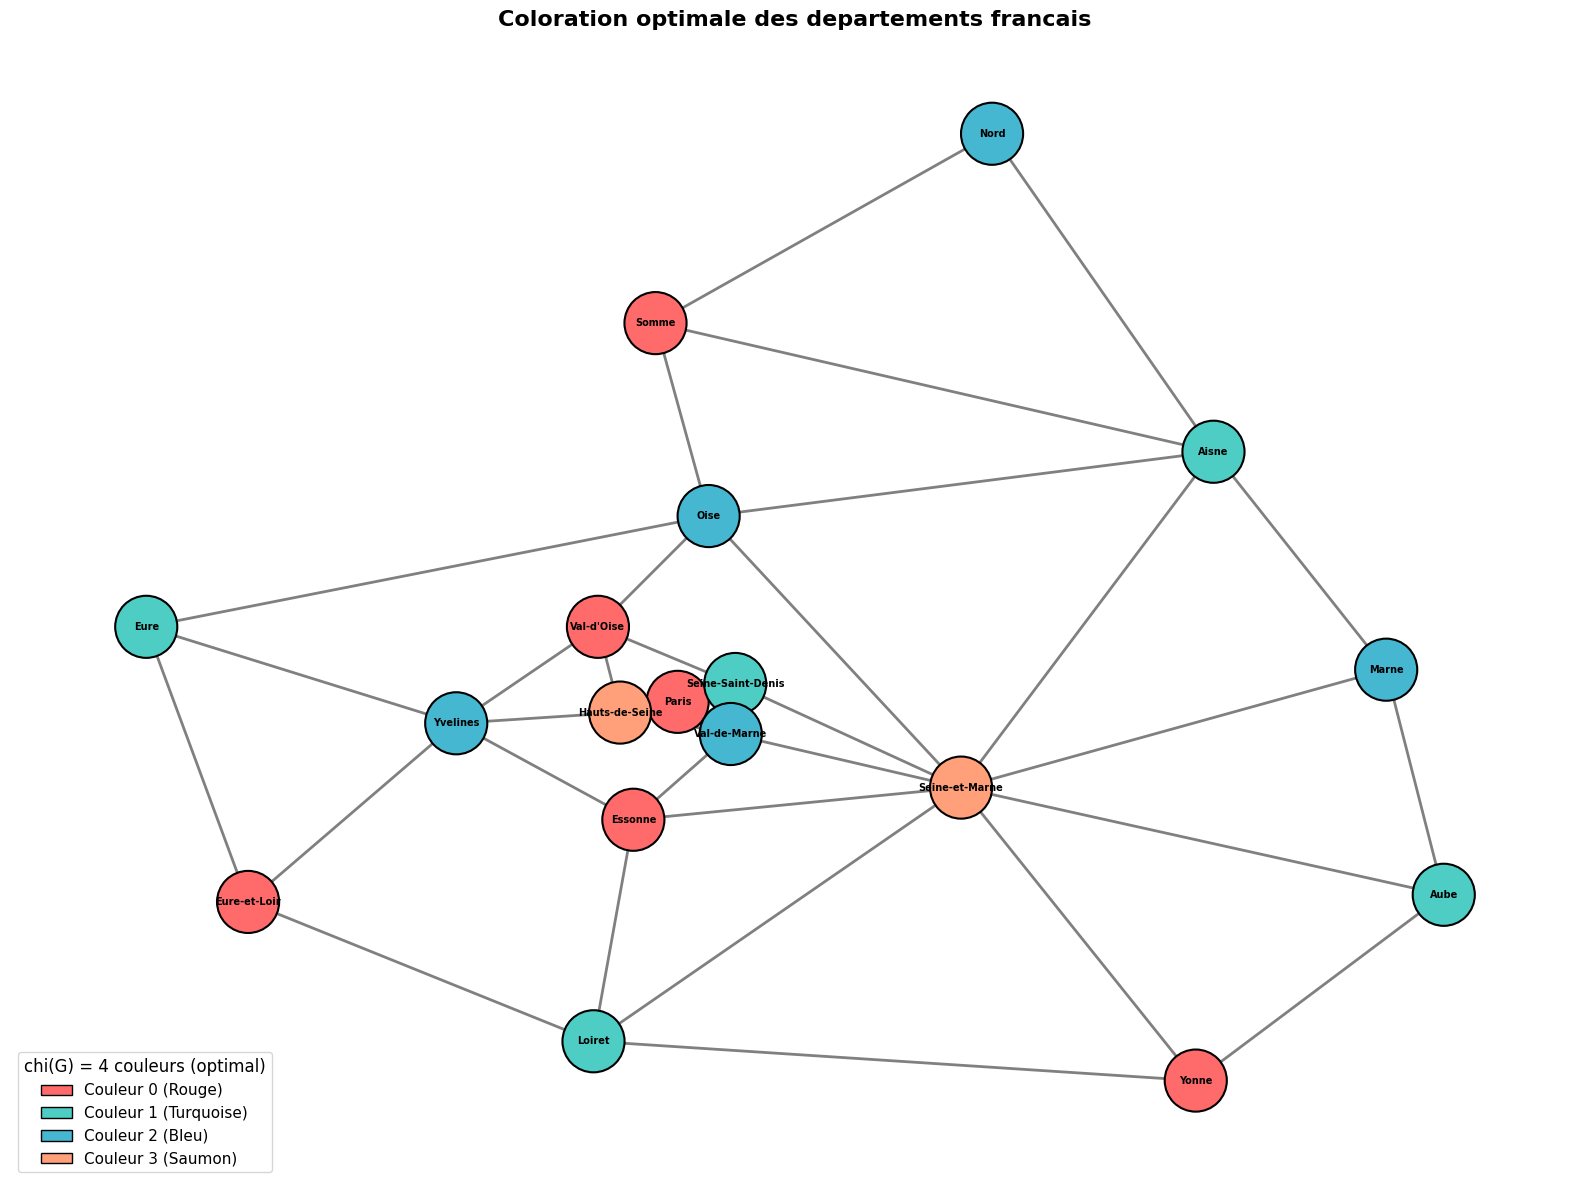

In [20]:
# Carte finale des departements avec coloration optimale
fig, ax = plt.subplots(1, 1, figsize=(16, 12))

palette = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8',
           '#F7DC6F', '#BB8FCE', '#85C1E9']
color_names = ['Rouge', 'Turquoise', 'Bleu', 'Saumon', 'Menthe',
               'Jaune', 'Violet', 'Bleu pale']

# Positions geographiques approximatives (longitude, latitude simplifiees)
geo_positions = {
    "Paris":             (2.35, 48.86),
    "Hauts-de-Seine":    (2.22, 48.83),
    "Seine-Saint-Denis": (2.48, 48.91),
    "Val-de-Marne":      (2.47, 48.77),
    "Essonne":           (2.25, 48.53),
    "Yvelines":          (1.85, 48.80),
    "Val-d'Oise":        (2.17, 49.07),
    "Seine-et-Marne":    (2.99, 48.62),
    "Oise":              (2.42, 49.38),
    "Aisne":             (3.56, 49.56),
    "Loiret":            (2.16, 47.91),
    "Eure-et-Loir":      (1.38, 48.30),
    "Eure":              (1.15, 49.07),
    "Marne":             (3.95, 48.95),
    "Aube":              (4.08, 48.32),
    "Yonne":             (3.52, 47.80),
    "Somme":             (2.30, 49.92),
    "Nord":              (3.06, 50.45),
}

node_colors = [palette[coloring_cpsat.get(node, 0) % len(palette)]
               for node in dept_graph.nodes()]

nx.draw(dept_graph, geo_positions, ax=ax,
        with_labels=True,
        node_color=node_colors,
        node_size=2000,
        font_size=7,
        font_weight='bold',
        edge_color='gray',
        width=2.0,
        edgecolors='black',
        linewidths=1.5,
        style='solid')

# Legende
legend_elements = [
    mpatches.Patch(facecolor=palette[i], edgecolor='black',
                   label=f'Couleur {i} ({color_names[i]})')
    for i in range(n_colors_cpsat)
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=11,
          title=f"chi(G) = {n_colors_cpsat} couleurs (optimal)",
          title_fontsize=12)

ax.set_title("Coloration optimale des departements francais",
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

***

## 7. Exemple guide

### Exemple guide 1 : Colorier les etats americains

Construisez un graphe simplifie de 10-12 etats americains contigus (par exemple la region des Grands Lacs : Ohio, Indiana, Illinois, Michigan, Wisconsin, Minnesota, Iowa, Missouri, Kentucky, West Virginia). Appliquez les trois algorithmes et comparez.

**Indice** : vous pouvez trouver les adjacences sur Wikipedia ("list of US states by border").

**Du cours a la pratique** : les trois exemples resolus de cette section reutilisent les fonctions definies plus
haut (``greedy_coloring``, ``dsatur_coloring``, ``cpsat_coloring``) sur de **nouveaux graphes** — la region des Grands Lacs
(11 etats, planaire), l'icosaedre, puis une comparaison Welsh-Powell vs DSATUR sur cinq graphes aleatoires.

La demarche attendue est systematique : (1) construire le graphe des adjacences, (2) appliquer les trois
approches, (3) comparer le compte de couleurs obtenu a la valeur optimale affichee, (4) ecrire une phrase qui
explique l'ecart eventuel (ou son absence). Les exercices 1b, 2b et 3b reprennent ces quatre etapes sur des
graphes que vous construisez vous-meme — la methode compte autant que le resultat.

In [21]:
# Exemple resolu : colorier les etats americains

us_adjacency = {
    "Ohio":          ["Indiana", "Kentucky", "West Virginia", "Michigan", "Pennsylvania"],
    "Indiana":       ["Ohio", "Illinois", "Kentucky", "Michigan"],
    "Illinois":      ["Indiana", "Iowa", "Missouri", "Kentucky", "Wisconsin"],
    "Michigan":      ["Ohio", "Indiana", "Wisconsin"],
    "Wisconsin":     ["Michigan", "Illinois", "Iowa", "Minnesota"],
    "Minnesota":     ["Wisconsin", "Iowa"],
    "Iowa":          ["Minnesota", "Wisconsin", "Illinois", "Missouri"],
    "Missouri":      ["Iowa", "Illinois", "Kentucky"],
    "Kentucky":      ["Ohio", "Indiana", "Illinois", "Missouri", "West Virginia"],
    "West Virginia": ["Ohio", "Kentucky", "Pennsylvania"],
    "Pennsylvania":  ["Ohio", "West Virginia"],
}

us_graph = nx.Graph()
for state, neighbors in us_adjacency.items():
    for n in neighbors:
        us_graph.add_edge(state, n)

for r in run_all_algorithms(us_graph, "US States"):
    print(f"{r['algorithm']:<25} {r['colors']} couleurs  ({r['optimal']})")


Greedy (Welsh-Powell)     3 couleurs  (Oui)
DSATUR                    3 couleurs  (Oui)
CP-SAT (OR-Tools)         3 couleurs  (Oui)


### Exemple guidé : les pays d'Europe de l'Ouest (contribution du groupe de la PR #21081)

*Contribution du groupe de la PR #21081, intégrée comme exemple guidé.*

L'exemple résolu plus haut colorait la région des Grands Lacs (11 États américains, 3 couleurs par les trois
approches). Celui-ci change d'échelle et de continent : **9 pays d'Europe de l'Ouest**, arêtes = frontières
**terrestres** uniquement (les voisins maritimes n'en créent pas), micro-États exclus.

La cellule suivante construit le dictionnaire d'adjacence (avec contrôle de symétrie des frontières),
applique `greedy_coloring` (ordre par défaut) puis les trois algorithmes via `run_all_algorithms`, prouve
l'optimum par CP-SAT, et affiche la carte avec la **clique** qui force la borne inférieure en rouge.

**À observer** : pourquoi ce graphe demande-t-il une couleur de plus que les Grands Lacs ? La réponse tient à
une clique de taille 4 — et à la planarité, qui fournit la borne supérieure.

Graphe Europe de l'Ouest
Sommets  : 9
Aretes   : 14
Planaire : True
Plus grande clique : ['Allemagne', 'Belgique', 'France', 'Luxembourg'] (taille 4)

Greedy (ordre par defaut) : 4 couleurs
Valide : True

Greedy (Welsh-Powell)     4 couleurs  (optimal : Oui)
DSATUR                    4 couleurs  (optimal : Oui)
CP-SAT (OR-Tools)         4 couleurs  (optimal : Oui)

CP-SAT : chi = 4, statut OPTIMAL
Encadrement : clique 4 <= chi <= 4 (quatre couleurs)


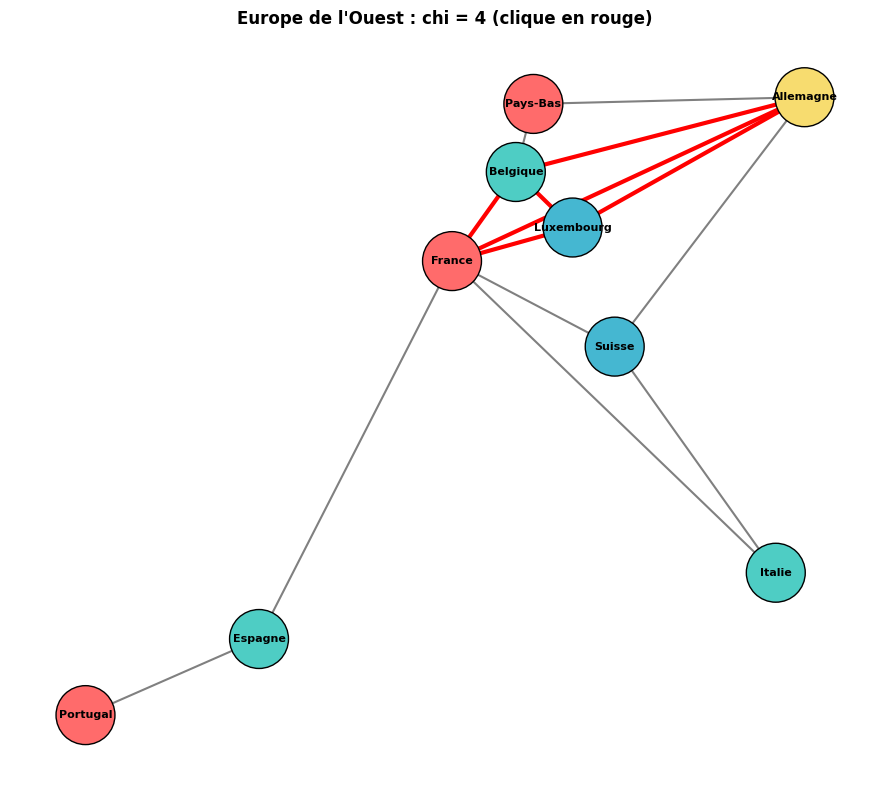

In [22]:
# Exemple guide : les pays d'Europe de l'Ouest (contribution du groupe de la PR #21081)

# Hypotheses : 9 pays, frontieres TERRESTRES uniquement (pas de voisin maritime),
# micro-Etats exclus (Andorre, Monaco, Liechtenstein, Saint-Marin, Vatican).
# Les frontieres avec des pays hors selection (Danemark, Pologne, Autriche...)
# ne creent pas d'arete puisque ces pays ne sont pas des sommets du graphe.
europe_adjacency = {
    "France":     ["Espagne", "Belgique", "Luxembourg", "Allemagne", "Suisse", "Italie"],
    "Espagne":    ["France", "Portugal"],
    "Portugal":   ["Espagne"],
    "Belgique":   ["France", "Pays-Bas", "Luxembourg", "Allemagne"],
    "Pays-Bas":   ["Belgique", "Allemagne"],
    "Luxembourg": ["France", "Belgique", "Allemagne"],
    "Allemagne":  ["France", "Belgique", "Pays-Bas", "Luxembourg", "Suisse"],
    "Suisse":     ["France", "Allemagne", "Italie"],
    "Italie":     ["France", "Suisse"],
}

# Controle de coherence : une frontiere est toujours declaree des deux cotes
for pays, voisins in europe_adjacency.items():
    for v in voisins:
        assert pays in europe_adjacency[v], f"frontiere {pays}-{v} non symetrique"

europe_graph = nx.Graph()
for pays, voisins in europe_adjacency.items():
    europe_graph.add_node(pays)
    for v in voisins:
        europe_graph.add_edge(pays, v)

print("Graphe Europe de l'Ouest")
print("=" * 45)
print(f"Sommets  : {europe_graph.number_of_nodes()}")
print(f"Aretes   : {europe_graph.number_of_edges()}")
print(f"Planaire : {nx.is_planar(europe_graph)}")

# Borne inferieure : une clique de taille k impose au moins k couleurs
max_clique = max(nx.find_cliques(europe_graph), key=len)
print(f"Plus grande clique : {sorted(max_clique)} (taille {len(max_clique)})")

# 1) greedy_coloring (ordre par defaut), comme demande par la consigne
coloring_eu, n_eu = greedy_coloring(europe_graph)
valid_eu, conflict_eu = validate_coloring(europe_graph, coloring_eu)
print(f"\nGreedy (ordre par defaut) : {n_eu} couleurs")
print(f"Valide : {valid_eu}")

# 2) Les trois approches, avec le nombre chromatique prouve par CP-SAT
print()
eu_results = run_all_algorithms(europe_graph, "Europe de l'Ouest")
for r in eu_results:
    print(f"{r['algorithm']:<25} {r['colors']} couleurs  (optimal : {r['optimal']})")

coloring_eu_opt, chi_eu, stats_eu = cpsat_coloring(europe_graph)
assert validate_coloring(europe_graph, coloring_eu_opt)[0]
print(f"\nCP-SAT : chi = {chi_eu}, statut {stats_eu['status']}")
print(f"Encadrement : clique {len(max_clique)} <= chi <= 4 (quatre couleurs)")

assert valid_eu and europe_graph.number_of_edges() <= 15
assert stats_eu['status'] == 'OPTIMAL' and chi_eu == len(max_clique)

# Carte (positions approximatives des capitales : longitude, latitude)
capitales = {
    "France": (2.35, 48.86), "Espagne": (-3.70, 40.42), "Portugal": (-9.14, 38.72),
    "Belgique": (4.35, 50.85), "Pays-Bas": (4.90, 52.37), "Luxembourg": (6.13, 49.61),
    "Allemagne": (13.40, 52.52), "Suisse": (7.45, 46.95), "Italie": (12.50, 41.90),
}
palette_eu = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#F7DC6F', '#BB8FCE']
fig, ax = plt.subplots(figsize=(9, 8))
nx.draw(europe_graph, capitales, ax=ax, with_labels=True,
        node_color=[palette_eu[coloring_eu_opt[p]] for p in europe_graph.nodes()],
        node_size=1800, font_size=8, font_weight='bold',
        edge_color='gray', width=1.5, edgecolors='black')
clique_edges = [(u, v) for u in max_clique for v in max_clique if u < v]
nx.draw_networkx_edges(europe_graph, capitales, edgelist=clique_edges,
                       ax=ax, edge_color='red', width=3)
ax.set_title(f"Europe de l'Ouest : chi = {chi_eu} (clique en rouge)", fontweight='bold')
plt.tight_layout()
plt.show()

### Interprétation : exemple guidé Europe de l'Ouest

**Sortie obtenue** : le graphe compte **9 pays et 14 frontières terrestres** (sous la limite d'une quinzaine). Il est planaire. `greedy_coloring` dans l'ordre par défaut produit une coloration **valide à 4 couleurs** (`Valide : True`), et CP-SAT prouve que **χ = 4** (statut `OPTIMAL`). Les trois approches atteignent donc l'optimum.

| Hypothèse de construction | Conséquence |
|---|---|
| Frontières terrestres uniquement | Pas d'arête France–Royaume-Uni ni Espagne–Italie, conformément à la consigne |
| Micro-États exclus (Andorre, Monaco, Liechtenstein…) | Le graphe reste lisible ; ils n'ajouteraient que des sommets de faible degré |
| Pays hors sélection ignorés | La frontière Allemagne–Autriche, par exemple, ne crée pas d'arête |

**Pourquoi 4 est optimal, sans même lancer de solveur ?** France, Belgique, Luxembourg et Allemagne sont **voisins deux à deux** (en rouge sur la carte) : ils forment une clique $K_4$, qui impose 4 couleurs différentes, donc $\chi \geq 4$. Le graphe est planaire, donc le théorème des quatre couleurs donne $\chi \leq 4$. On obtient l'encadrement $4 \leq \chi \leq 4$. CP-SAT ne fait que **confirmer** par la recherche ce que ce raisonnement établit déjà.

**Contraste avec l'exemple précédent** : les 11 États des Grands Lacs se colorent en 3 couleurs, car aucun groupe de 4 États n'y est mutuellement voisin. Ici, le Luxembourg, enclavé entre trois pays eux-mêmes voisins, suffit à forcer une quatrième couleur.

> **À retenir** : une **clique** fournit une borne inférieure, et la planarité (ou un algorithme) une borne supérieure. Quand les deux bornes coïncident, l'optimalité est démontrée.

#### Exercice 1b : Colorier les pays d'Amérique du Sud

L'exemple guidé portait sur l'Europe de l'Ouest. À vous de produire l'équivalent pour un autre continent :
l'Amérique du Sud (10 pays : Colombie, Venezuela, Brésil, Équateur, Pérou, Bolivie, Paraguay, Argentine,
Chili, Uruguay). Comme précédemment, les arêtes sont les frontières **terrestres** : les pays hors sélection
(Panama, Guyana, Suriname, Guyane française) ne créent pas d'arêtes.

**Consignes** : définir le dictionnaire d'adjacence (contrôle de symétrie conseillé), construire le graphe,
lui appliquer `greedy_coloring` et les trois algorithmes, comparer au nombre chromatique prouvé par CP-SAT,
et trouver la **clique de taille 4** qui force la borne inférieure.

**Pour vérifier votre travail** : votre graphe doit avoir 10 sommets et 19 arêtes ; il est planaire ; le
greedy doit trouver une coloration valide et CP-SAT doit rendre `OPTIMAL` avec chi = 4.

In [23]:
# Exercice 1b : Colorier les pays d'Amerique du Sud

# TODO: definissez le dictionnaire d'adjacence sudamerica_adjacency (10 pays)
# TODO: controlez la symetrie des frontieres, puis construisez le graphe
# TODO: greedy_coloring, les trois algorithmes, puis CP-SAT : chi obtenu ?
# TODO: trouvez la clique de taille 4 qui prouve la borne inferieure
# Indice : le Bresil partage une frontiere terrestre avec 7 des 9 autres pays
#  (tous sauf le Chili et l'Equateur) ; la Bolivie touche 5 pays.

# Votre code ici
print("Exercice a completer")

Exercice a completer


### Exemple guide 2 : Borne superieure du greedy et planarite

L'icosaedre est le second graphe de reference : 12 sommets, 30 aretes, regulier de degre 5, et **planaire** — le
theoreme des quatre couleurs s'applique donc, et une coloration en 4 couleurs doit exister.

La cellule suivante evalue le pire cas du greedy sur ce graphe : elle compare une coloration gloutonne dans un ordre
defavorable a l'optimum exact. C'est le test de la borne superieure : meme mal ordonne, le greedy reste-t-il sous la
garantie 4 ? (L'ordre par defaut d'un graphe regulier etant arbitraire, ce n'est pas forcement le pire cas reel —
le notebook mesure ce qui se produit, il n'essaie pas d'exhiber le pire.)


In [24]:
# Exemple resolu : borne superieure du greedy sur l'icosahedre

icosahedron = nx.icosahedral_graph()
_, n_opt, _ = cpsat_coloring(icosahedron)

worst = 0
for seed in range(30):
    _, n = greedy_coloring(icosahedron, order_random(icosahedron, seed=seed))
    worst = max(worst, n)

print(f"optimum = {n_opt}, pire greedy = {worst}")


optimum = 4, pire greedy = 6


### Exemple guidé : comparaison greedy vs optimal sur le dodécaèdre (contribution du groupe de la PR #21081)

*Contribution du groupe de la PR #21081, intégrée comme exemple guidé.*

Le dodécaèdre est le jumeau régulier de l'icosaèdre pour la planarité : **20 sommets, 30 arêtes, degré 3** —
un des cinq solides platoniciens. La cellule suivante charge `nx.dodecahedral_graph()`, applique le greedy
(ordre par défaut, puis degré décroissant), DSATUR et la recherche optimale par CP-SAT, puis répète le greedy
sur 30 ordres aléatoires pour mesurer le pire cas, avant de confronter le tout aux bornes théoriques
(Delta + 1, Brooks).

**À observer** : quel algorithme atteint l'optimum, et pourquoi le tri par degré décroissant ne change rien ici
(le graphe est régulier) — tandis que la valeur exacte réserve une surprise par rapport à la borne de planarité.

In [25]:
# Exemple guide : comparaison greedy vs optimal sur le dodecahedre (contribution du groupe de la PR #21081)

dodecahedron = nx.dodecahedral_graph()
degres = set(dict(dodecahedron.degree()).values())

print("Dodecaedre")
print("=" * 45)
print(f"Sommets : {dodecahedron.number_of_nodes()}, aretes : {dodecahedron.number_of_edges()}, "
      f"degres : {degres}")
print(f"Planaire : {nx.is_planar(dodecahedron)}, biparti : {nx.is_bipartite(dodecahedron)}")

# Les trois approches demandees
_, n_greedy_def = greedy_coloring(dodecahedron)                       # ordre par defaut
order_desc = order_by_degree_desc(dodecahedron)
_, n_greedy_desc = greedy_coloring(dodecahedron, order_desc)          # degre decroissant
_, n_dsatur_dod = dsatur_coloring(dodecahedron)
col_opt_dod, chi_dod, stats_dod = cpsat_coloring(dodecahedron)

print(f"\n{'Algorithme':<30} {'Couleurs':>8}")
print("-" * 40)
print(f"{'Greedy (ordre par defaut)':<30} {n_greedy_def:>8}")
print(f"{'Greedy (degre decroissant)':<30} {n_greedy_desc:>8}")
print(f"{'DSATUR':<30} {n_dsatur_dod:>8}")
print(f"{'CP-SAT (' + stats_dod['status'] + ')':<30} {chi_dod:>8}")

# Le tri par degre ne change rien sur un graphe regulier
print(f"\nOrdre degre decroissant identique a l'ordre par defaut : "
      f"{order_desc == list(dodecahedron.nodes())}")

# Meme protocole que l'exemple guide (icosaedre) : pire cas sur 30 ordres aleatoires
counts = [greedy_coloring(dodecahedron, order_random(dodecahedron, seed=s))[1]
          for s in range(30)]
print(f"Greedy sur 30 ordres aleatoires : min = {min(counts)}, max = {max(counts)}, "
      f"repartition = { {k: counts.count(k) for k in sorted(set(counts))} }")

# Bornes theoriques
delta = max(degres)
print(f"\nBorne du greedy  : chi <= Delta + 1 = {delta + 1}")
print(f"Borne de Brooks  : chi <= Delta = {delta} (graphe connexe, ni complet ni cycle impair)")
print(f"Borne inferieure : chi >= 3 (graphe non biparti : il contient des cycles impairs)")

assert stats_dod['status'] == 'OPTIMAL' and chi_dod == 3
assert validate_coloring(dodecahedron, col_opt_dod)[0]
assert max(counts) <= delta + 1

Dodecaedre
Sommets : 20, aretes : 30, degres : {3}
Planaire : True, biparti : False



Algorithme                     Couleurs
----------------------------------------
Greedy (ordre par defaut)             4
Greedy (degre decroissant)            4
DSATUR                                3
CP-SAT (OPTIMAL)                      3

Ordre degre decroissant identique a l'ordre par defaut : True
Greedy sur 30 ordres aleatoires : min = 3, max = 4, repartition = {3: 11, 4: 19}

Borne du greedy  : chi <= Delta + 1 = 4
Borne de Brooks  : chi <= Delta = 3 (graphe connexe, ni complet ni cycle impair)
Borne inferieure : chi >= 3 (graphe non biparti : il contient des cycles impairs)


### Interprétation : exemple guidé du dodécaèdre

**Sortie obtenue** : le greedy utilise **4 couleurs**, que ce soit dans l'ordre par défaut ou par degré décroissant. DSATUR en utilise **3**, et CP-SAT prouve que **χ = 3** (statut `OPTIMAL`). Le greedy n'atteint donc **pas** l'optimum, mais DSATUR l'atteint.

**Le piège de la borne supérieure** : l'optimum n'est **pas 4 mais 3**. La planarité ne donne qu'une **borne supérieure** (χ ≤ 4), pas la valeur exacte. Pour le dodécaèdre, deux arguments donnent la valeur exacte :
- **Borne supérieure (théorème de Brooks, 1941)** : un graphe connexe qui n'est ni complet ni un cycle impair vérifie χ ≤ Δ. Ici Δ = 3, donc χ ≤ 3.
- **Borne inférieure** : le graphe n'est pas biparti, car ses faces sont des pentagones, donc des cycles impairs. Il faut donc au moins 3 couleurs.

D'où χ = 3, ce que CP-SAT confirme.

| Question | Réponse |
|---|---|
| Le greedy atteint-il l'optimum ? | Non dans l'ordre par défaut (4 contre 3). Sur 30 ordres aléatoires, il donne 3 couleurs 11 fois et 4 couleurs 19 fois. |
| Pourquoi le tri par degré décroissant aurait-il dû protéger l'heuristique ? | **Il ne le peut pas ici** : le dodécaèdre est **régulier** (tous les sommets sont de degré 3). Le tri ne départage personne et redonne exactement l'ordre par défaut, comme le montre la sortie `True`. |
| Le greedy peut-il dépasser 4 ? | Non : il n'utilise jamais plus de Δ + 1 = 4 couleurs, et le maximum observé est bien 4. |

**Pourquoi DSATUR réussit-il là où le greedy échoue ?** Sur un graphe régulier, le degré ne contient aucune information, mais la **saturation** si : elle évolue pendant la coloration. DSATUR traite d'abord les sommets que leurs voisins contraignent déjà, ce qu'un ordre statique ne peut pas faire.

> **À retenir** : le théorème des quatre couleurs donne une borne supérieure, pas la valeur exacte. Et une heuristique fondée sur le degré est aveugle sur un graphe régulier.

#### Exercice 2b : Cube et octaèdre — les solides platoniciens restants

L'exemple guidé a traité le dodécaèdre (et l'exemple 2, l'icosaèdre). À vous de compléter l'inventaire avec les
deux solides restants : le **cube** (`nx.hypercube_graph(3)` : 8 sommets, 12 arêtes, degré 3, biparti) et
l'**octaèdre** (`nx.octahedral_graph()` : 6 sommets, 12 arêtes, degré 4).

**Consignes** : pour chacun, appliquer `greedy_coloring` (ordre par défaut), `dsatur_coloring` et
`cpsat_coloring`. Sur le **cube**, cherchez des ordres (ex. `order_random`) où le greedy dépasse l'optimum :
il peut monter jusqu'à Delta + 1 = 4 alors que chi = 2. Sur l'**octaèdre**, échantillonnez des ordres et
comptez combien dépassent l'optimum.

**Pour vérifier votre travail** : cube chi = 2 (biparti), octaèdre chi = 3 (il contient des triangles) —
CP-SAT doit rendre `OPTIMAL` sur les deux ; sur le cube une part notable des ordres aléatoires dépasse 2 ;
sur l'octaèdre, aucun ordre ne dépasse 3 (votre échantillon doit le confirmer).

In [26]:
# Exercice 2b : Cube et octaedre -- les solides platoniciens restants

# TODO: chargez le cube (nx.hypercube_graph(3)) et l'octaedre (nx.octahedral_graph())
# TODO: pour chaque graphe : greedy (ordre par defaut), DSATUR, CP-SAT ; comparez
# TODO: cube : cherchez des ordres (order_random) ou le greedy depasse chi = 2
#  (il peut atteindre Delta + 1 = 4)
# TODO: octaedre : echantillonnez des ordres, comptez ceux qui depassent chi = 3
# Indice : le cube est biparti (chi = 2) ; l'octaedre contient des triangles (chi >= 3)

# Votre code ici
print("Exercice a completer")

Exercice a completer


### Exemple guide 3 : Implementer Welsh-Powell et comparer avec DSATUR

L'exemple precedent a pose la borne superieure du greedy. Ici, on enrichit la comparaison en implementant
**Welsh-Powell** (la variante du greedy qui trie les sommets par degre decroissant puis colore chaque sommet avec la
plus petite couleur disponible — le meme algorithme que la ligne « degre decroissant » du debut du notebook), et on
le confronte a DSATUR sur **cinq graphes aleatoires**.

La cellule suivante genere cinq graphes G0 a G4 (graines fixees, deterministes) et affiche, pour chacun : le compte
de Welsh-Powell (WP), de DSATUR, et l'optimum calcule par CP-SAT. A vous de lire l'ecart : WP est-il systematiquement
battu ? Par combien de couleurs ? Sur quelles graines DSATUR atteint-il l'optimum ?


In [27]:
# Exemple resolu : Welsh-Powell et comparaison avec DSATUR

def welsh_powell_coloring(G):
    coloring = {}
    sorted_vertices = sorted(G.nodes(), key=lambda v: G.degree(v), reverse=True)
    uncolored = set(sorted_vertices)
    color = 0
    while uncolored:
        layer = []
        for v in sorted_vertices:
            if v not in uncolored:
                continue
            if all(not G.has_edge(u, v) for u in layer):
                layer.append(v)
                coloring[v] = color
                uncolored.remove(v)
        color += 1
    return coloring, max(coloring.values()) + 1


for i in range(5):
    G = nx.erdos_renyi_graph(50, 0.3, seed=i)
    _, n_wp = welsh_powell_coloring(G)
    _, n_ds = dsatur_coloring(G)
    _, n_cp, _ = cpsat_coloring(G, time_limit=10)
    print(f"G{i}: WP={n_wp}, DSATUR={n_ds}, optimal={n_cp}")


G0: WP=9, DSATUR=7, optimal=6


G1: WP=8, DSATUR=7, optimal=6


G2: WP=8, DSATUR=7, optimal=6
G3: WP=7, DSATUR=7, optimal=6


G4: WP=7, DSATUR=7, optimal=6


### Exemple guidé : implémenter DSATUR manuellement (contribution du groupe de la PR #21081)

*Contribution du groupe de la PR #21081, intégrée comme exemple guidé.*

Les exemples précédents ont *utilisé* les algorithmes ; celui-ci **réimplémente DSATUR** pas à pas —
l'équivalent exact de `dsatur_coloring` vu en début de carnet. La cellule suivante définit
`dsatur_manuel(g, ordre=None)` (saturation maximale, départage par degré puis par position), la confronte à
`dsatur_coloring` sur le graphe des départements et sur les cinq graphes aléatoires G0 à G4, teste six cas
limites, et mesure la stabilité du départage sur 30 ordres.

**À observer** : le compte de couleurs est robuste, l'affectation ne l'est pas — et la trace de
`dsatur_coloring` peut varier d'une exécution à l'autre, ce que `dsatur_manuel` évite en fixant explicitement
sa règle de départage.

In [28]:
# Exemple guide : DSATUR implemente manuellement (contribution du groupe de la PR #21081)

def dsatur_manuel(g, ordre=None):
    """DSATUR (Brelaz 1979) reimplemente pas a pas.

    A chaque etape, choisit le sommet non colore de saturation maximale
    (nombre de couleurs distinctes chez ses voisins deja colores), departage
    par le degre maximal, puis par la position dans `ordre` (le premier gagne).

    Args:
        g: graphe NetworkX
        ordre: liste des sommets, sert au departage final (defaut : g.nodes())

    Returns:
        affectations: liste de (etape, sommet, saturation, degre, couleur)
                      dans l'ordre ou les sommets ont ete colores
        n_couleurs: nombre de couleurs utilisees (0 pour un graphe vide)
    """
    if ordre is None:
        ordre = list(g.nodes())
    assert set(ordre) == set(g.nodes()), "ordre doit contenir chaque sommet une fois"
    position = {v: i for i, v in enumerate(ordre)}

    couleur = {}
    # saturation[v] = ensemble des couleurs deja prises par les voisins de v
    saturation = {v: set() for v in g.nodes()}
    affectations = []

    for etape in range(1, g.number_of_nodes() + 1):
        # Choix du sommet : saturation max, puis degre max, puis premier dans l'ordre
        meilleur = None
        for v in ordre:
            if v in couleur:
                continue
            cle = (len(saturation[v]), g.degree(v), -position[v])
            if meilleur is None or cle > meilleur_cle:
                meilleur, meilleur_cle = v, cle

        # Plus petite couleur absente du voisinage
        c = 0
        while c in saturation[meilleur]:
            c += 1
        couleur[meilleur] = c
        affectations.append((etape, meilleur, len(saturation[meilleur]),
                             g.degree(meilleur), c))

        # Mise a jour incrementale de la saturation des voisins non colores
        for voisin in g.neighbors(meilleur):
            if voisin not in couleur:
                saturation[voisin].add(c)

    n_couleurs = max(couleur.values()) + 1 if couleur else 0
    return affectations, n_couleurs


# L'enonce d'origine nommait aussi dsatur_manual : on garde les deux orthographes
dsatur_manual = dsatur_manuel


def vers_coloration(affectations):
    """Convertit le tableau d'affectations en dict sommet -> couleur."""
    return {sommet: c for (_e, sommet, _s, _d, c) in affectations}


# --- 1) Departements : meme nombre de couleurs que dsatur_coloring ---
aff_dept, n_dept = dsatur_manuel(dept_graph)
assert validate_coloring(dept_graph, vers_coloration(aff_dept))[0]
print(f"Departements : dsatur_manuel = {n_dept}, dsatur_coloring = {n_colors_dsatur}")
print(f"\n{'Etape':<6} {'Sommet':<20} {'Sat':>4} {'Deg':>4} {'Couleur':>8}")
print("-" * 46)
for etape, sommet, sat, deg, c in aff_dept:
    print(f"{etape:<6} {sommet:<20} {sat:>4} {deg:>4} {c:>8}")
assert n_dept == n_colors_dsatur

# --- 2) G0 a G4 : reproduire la colonne DSATUR de l'exemple guide ---
print(f"\n{'Graphe':<7} {'manuel':>7} {'dsatur_coloring':>16} {'coloration identique':>21}")
print("-" * 55)
for i in range(5):
    G = nx.erdos_renyi_graph(50, 0.3, seed=i)
    aff, n_man = dsatur_manuel(G)
    col_man = vers_coloration(aff)
    col_ref, n_ref = dsatur_coloring(G)
    assert validate_coloring(G, col_man)[0] and n_man == n_ref
    print(f"G{i:<6} {n_man:>7} {n_ref:>16} {str(col_man == col_ref):>21}")

# --- 3) Cas limites, avec la valeur exacte attendue ---
cas_limites = [
    ("graphe vide",             nx.empty_graph(0),  0),
    ("5 sommets isoles",        nx.empty_graph(5),  1),
    ("complet K5",              nx.complete_graph(5), 5),
    ("cycle pair C6 (biparti)", nx.cycle_graph(6),  2),
    ("cycle impair C7",         nx.cycle_graph(7),  3),
    ("grille 4x4 (bipartie)",   nx.grid_2d_graph(4, 4), 2),
]
print(f"\n{'Cas limite':<26} {'manuel':>7} {'attendu':>8}")
print("-" * 43)
for nom, G, attendu in cas_limites:
    aff, n_man = dsatur_manuel(G)
    assert validate_coloring(G, vers_coloration(aff))[0] and n_man == attendu
    print(f"{nom:<26} {n_man:>7} {attendu:>8}")

# --- 4) Role du departage : le compte est stable, l'affectation ne l'est pas ---
# On ne change que l'ordre de departage (parametre ordre) sur les departements.
comptes, colorations = [], set()
for seed in range(30):
    aff, n_man = dsatur_manuel(dept_graph, ordre=order_random(dept_graph, seed=seed))
    comptes.append(n_man)
    colorations.add(tuple(sorted(vers_coloration(aff).items())))
print(f"\n30 ordres de departage : comptes = { {k: comptes.count(k) for k in sorted(set(comptes))} }, "
      f"colorations distinctes = {len(colorations)}")
print("\nTous les controles passent.")

Departements : dsatur_manuel = 4, dsatur_coloring = 4

Etape  Sommet                Sat  Deg  Couleur
----------------------------------------------
1      Seine-et-Marne          0    9        0
2      Seine-Saint-Denis       1    5        1
3      Val-de-Marne            2    5        2
4      Hauts-de-Seine          2    5        0
5      Paris                   3    3        3
6      Val-d'Oise              2    4        2
7      Yvelines                2    5        1
8      Essonne                 3    4        3
9      Oise                    2    5        1
10     Aisne                   2    5        2
11     Loiret                  2    4        1
12     Marne                   2    3        1
13     Aube                    2    3        2
14     Yonne                   3    3        3
15     Somme                   2    3        0
16     Nord                    2    2        1
17     Eure                    1    3        0
18     Eure-et-Loir            2    3        2

Grap

### Interprétation : exemple guidé DSATUR manuel

**Sortie obtenue** : `dsatur_manuel` colore les départements en **4 couleurs**, comme `dsatur_coloring`. Sur les graphes G0 à G4, il reproduit la colonne DSATUR de l'exemple guidé (**7 couleurs** chacun) avec une coloration **identique sommet par sommet** à celle de `dsatur_coloring`. Il donne aussi la valeur exacte sur les six cas limites testés.

| Élément de la spécification | Mise en œuvre |
|---|---|
| (1) Parcourir les sommets dans l'ordre donné | La boucle de sélection suit `ordre` ; la position dans `ordre` sert de dernier critère de départage |
| (2) Saturation max, puis degré max | Clé de choix `(saturation, degré, -position)` : le plus grand l'emporte |
| (3) Plus petite couleur absente du voisinage | `saturation[v]` contient déjà les couleurs voisines : on prend le premier entier absent |
| (4) Tableau des affectations et nombre de couleurs | Liste `(étape, sommet, saturation, degré, couleur)` dans l'ordre de coloration |

La saturation est mise à jour **de façon incrémentale** : à chaque coloration, on ajoute la couleur choisie aux ensembles des voisins non colorés, au lieu de la recalculer. Le coût total reste en $O(V^2 + E)$, comme l'implémentation de référence. La fonction porte les deux orthographes : `dsatur_manuel` et `dsatur_manual`.

**Cas limites** : graphe vide (0 couleur, alors que `dsatur_coloring` échouerait en appelant `max()` sur un dictionnaire vide), sommets isolés (1), $K_5$ (5), cycles pair (2) et impair (3), grille bipartie (2). Sur les graphes bipartis, DSATUR trouve bien 2 couleurs, ce qui illustre la propriété citée en section 4.

**Observation importante : le départage.** Sur 30 ordres de départage différents, DSATUR utilise **toujours 4 couleurs**, mais produit **7 colorations distinctes**. Le compte est robuste, l'affectation ne l'est pas. Cela explique une différence visible dans ce notebook : `dsatur_coloring` choisit parmi les sommets à égalité en parcourant un `set` de chaînes, dont l'ordre change à chaque démarrage de Python (randomisation des hash). Le détail de sa trace peut donc varier d'une exécution à l'autre : parmi les voisins également saturés de Seine-et-Marne, deux sommets de même degré — Oise et Aisne, par exemple — peuvent être examinés dans un ordre ou dans l'autre. `dsatur_manuel`, qui départage selon un ordre explicite, donne le même résultat à chaque exécution.

> **À retenir** : un algorithme glouton n'est entièrement spécifié qu'avec sa **règle de départage**. Pour comparer deux implémentations, il faut fixer cette règle, sinon seuls les comptes sont comparables, et pas les affectations.

#### Exercice 3b : Colorier les arêtes via le graphe des arêtes

Les exemples ont toujours colorié des **sommets**. Cet exercice change d'objet : colorier les **arêtes** —
deux arêtes qui partagent un sommet reçoivent des couleurs différentes. La réduction classique ramène ce
problème à une coloration de sommets sur le **graphe des arêtes** (`nx.line_graph(G)` : ses sommets sont les
arêtes de G, deux sommets y sont voisins quand les arêtes partagent une extrémité).

**Consignes** : écrire `edge_coloring(G, ordre=None)` qui colore `nx.line_graph(G)` avec `greedy_coloring`
(ou `dsatur_coloring`) puis redescend les couleurs sur les arêtes de G. Vérifier le résultat sur le **cube**
(12 arêtes), sur **K4** (6 arêtes) et sur le **graphe de Petersen** (15 arêtes).

**Pour vérifier votre travail** : les arêtes d'une même couleur doivent former un **couplage** (aucune
extrémité partagée) ; chi'(cube) = 3 (König : graphe biparti) — mais le greedy naïf y trouve souvent 4,
c'est l'ordre qui compte encore ; chi'(K4) = 3 ; chi'(Petersen) = 4 quelle que soit la méthode (borne de
Vizing : Delta <= chi' <= Delta + 1 avec Delta = 3).

In [29]:
# Exercice 3b : Colorier les aretes via le graphe des aretes

# TODO: implementez edge_coloring(G, ordre=None) :
#  - L = nx.line_graph(G) ; ses sommets sont les aretes (u, v) de G
#  - colorez L avec greedy_coloring(L, ordre) (ou dsatur_coloring(L))
#  - redescendez : couleur de l'arete (u, v) = couleur du sommet (u, v) dans L
# TODO: verifiez sur le cube, K4 et le graphe de Petersen (nx.petersen_graph())
# TODO: pour chaque couleur, verifiez que les aretes forment un couplage
#  (deux aretes de meme couleur ne partagent aucun sommet)
# Indice : sur le cube, chi' = 3 mais le greedy peut en trouver 4 selon l'ordre ;
#  DSATUR ou un ordre trie atteignent 3

# Votre code ici
print("Exercice a completer")

Exercice a completer


***

## Recapitulatif

### Resume des algorithmes

| Algorithme | Type | Complexite | Qualite | Garantie |
|------------|------|-----------|---------|----------|
| **Greedy** | Heuristique constructive | $O(V + E)$ | $\leq \Delta(G) + 1$ couleurs | Borne superieure |
| **DSATUR** | Heuristique adaptative | $O(V^2)$ | Souvent optimal | Aucune (exact pour bipartis) |
| **CP-SAT** | Solveur exact | Exponentiel pire cas | Optimal ($\chi(G)$) | Preuve d'optimalite |

### Ce que nous avons appris

1. La **coloration de graphe** est un problème NP-difficile fondamental avec de nombreuses applications
2. L'**ordre des sommets** a un impact majeur sur la qualite de la coloration gloutonne
3. **DSATUR** adapte dynamiquement l'ordre en privilegiant les sommets les plus satures (analogie avec MRV en CSP)
4. **CP-SAT** garantit l'optimalite mais ne passe pas a l'echelle sur les grands graphes
5. Le **theoreme des quatre couleurs** borne le nombre chromatique des graphes planaires

### Pour aller plus loin

- **Tabu Search** : ameliorer une coloration par recherche locale avec liste tabu
- **Branch and Bound** : algorithme exact plus efficace que la brute force
- **Coloration de graphes d'intervalles** : cas polynomial important en planification
- **Coloration fractionnaire** : relaxation LP du problème de coloration

### References

- Brelaz, D. (1979). "New methods to color the vertices of a graph". *Communications of the ACM*, 22(4), 251-256.
- Welsh, D. J. A. & Powell, M. B. (1967). "An upper bound for the chromatic number of a graph". *The Computer Journal*, 10(1), 85-86.
- Appel, K. & Haken, W. (1976). "Every planar map is four colorable". *Bulletin of the AMS*, 82(5), 711-712.
- Karp, R. M. (1972). "Reducibility among combinatorial problems". *Complexity of Computer Computations*, 85-103.

**Ce qu'il faut retenir du notebook en trois lignes** :

1. Une coloration valide se trouve facilement (greedy), mais son cout depend de l'ordre choisi — l'ordre par degre
   decroissant est le reflexe sur-domine par DSATUR, qui choisit dynamiquement le sommet le plus contraint.
2. Trouver le **nombre chromatique exact** est NP-difficile : seul un solveur exact comme CP-SAT peut *prouver*
   l'optimalite (chi = 4 pour les departements, verifie en 85.2 ms), contre des dizaines de secondes des que le
   graphe atteint quelques dizaines de sommets.
3. Le choix de l'outil se prend donc en **connaissant la taille** : DSATUR en premier systematiquement, CP-SAT
   reserve aux petits graphes dont la preuve d'optimalite vaut le temps de calcul.